# 04 · Temporal extension: voting networks before and after the 2022 Løgting election

**DTU 02805 – Social Graphs and Interactions · network-analysis workstream**

This notebook extends `02_network_analysis.ipynb` (which stays the full-period baseline and is **not modified**). It asks how the MP–MP voting-similarity network differs before and after the **Faroese parliamentary (Løgting) election of 8 December 2022**, and — the central point — **how much of any difference comes from a different set of MPs rather than from the same MPs voting differently**.

Plan:

1. Establish the election timeline from sources, and what the vote data show around it.
2. Build separate pre- and post-election networks with identical definitions.
3. Compare the full parliaments (*composition*) and then only the *continuing* MPs (*behaviour*).
4. Re-assess the overlap threshold, null models, and the community structure.
5. Export tables, figures and results to `network_analysis/outputs/{tables,figures,results}/temporal/` and the two markdown reports to `network_analysis/reports/` (nothing else is written).

**What this notebook cannot do.** It makes no causal claim about the election: before/after differences also reflect the agenda, the calendar, a different pool of MPs and (according to secondary sources, see section 1) changed government/opposition roles, none of which can be separated here.

In [1]:
import sys, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "network_analysis" / "src" / "networks.py").exists():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "network_analysis" / "src"))
import networks as N      # existing helpers (unchanged)
import temporal as T      # new helpers for this notebook

SEED = 2805
THRESHOLDS = (10, 20, 30, 40)
SEEDS = range(SEED, SEED + 20)            # Louvain seeds for stability checks
OUT = "temporal"                          # written to network_analysis/outputs/{tables,figures,results}/temporal/ and network_analysis/reports/ (routing in N.output_path)
RULE_SHARE = 0.85                         # coverage rule that selects the temporal threshold (section 4)
EDGE_SHOW = 0.8                           # figure T2 only: draw pairs whose similarity is >= this (a drawing rule)
COMMON_THR = 20                           # threshold of the common pair sample for the speech comparison (section 10)
PERM_PARTY, PERM_DIV, PERM_SPLIT, PERM_MANTEL = 10_000, 1_000, 1_000, 5_000   # permutation counts (section 7)
R = {"parameters": {"seed": SEED, "thresholds": list(THRESHOLDS), "louvain_seeds": len(SEEDS),
                    "election": str(T.ELECTION.date()), "new_government": str(T.NEW_GOVERNMENT.date()),
                    "speech_window_end": str(N.WINDOW_END.date()), "coverage_rule_share": RULE_SHARE,
                    "figure_T2_edge_rule": EDGE_SHOW, "common_sample_threshold": COMMON_THR,
                    "permutations": {"party_label": PERM_PARTY, "within_division": PERM_DIV,
                                     "period_split": PERM_SPLIT, "mantel": PERM_MANTEL}}}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.facecolor": "white"})
INK, MUTED = "#1c1c1b", "#6b6a66"
C_PRE, C_POST, C_WIN = "#2a78d6", "#eb6834", "#1baf7a"     # pre / post (full) / post (speech window)

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(N.output_path(ROOT, OUT, "figures", f"{name}.{ext}"), dpi=300, bbox_inches="tight")

def save_table(df, name, index=False):
    df.to_csv(N.output_path(ROOT, OUT, name), index=index)

def caption(text):
    """Display Markdown built from computed values, so captions and comments never carry typed-in results."""
    display(Markdown(text))

def digest(root):
    """SHA-256 of every existing output under network_analysis/outputs/ outside the */temporal/ folders, to prove they stay untouched."""
    base = root / "network_analysis" / "outputs"
    return {str(p.relative_to(root)): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(base.rglob("*")) if p.is_file() and "temporal" not in p.relative_to(base).parts}
EXISTING_BEFORE = digest(ROOT)
print("existing outputs protected:", len(EXISTING_BEFORE), "files")

existing outputs protected: 21 files


## 1. The election timeline (sources)

Dates were checked against official and secondary sources (details and URLs in `network_analysis/reports/election_timeline.md`, written by section 2).

| Fact | Value | Source quality |
|---|---|---|
| Election to the **Løgting** (not the Danish Folketing election held in the Faroes on 31 Oct 2022) | **8 December 2022** | **Official**: government.fo (former prime ministers page: the previous coalition "lost the general election on 8 December 2022"); corroborated by Wikipedia (fo, en) |
| New Faroese government took office | **22 December 2022** (PM Aksel V. Johannesen) | **Official**: government.fo ("took office on 22 December 2022") |
| Coalition formed on 22 Dec 2022 | Javnaðarflokkurin, Tjóðveldi, Framsókn | *Secondary only*: en.wikipedia, in.fo (22 Dec 2022 report) |
| Previous government (14 Sep 2019 – 22 Dec 2022), PM Bárður á Steig Nielsen | Sambandsflokkurin, Fólkaflokkurin, Miðflokkurin (Miðflokkurin left the coalition in Nov 2022) | *Secondary only*: en.wikipedia (2019 and 2022 election pages), fo.wikipedia |
| Seats 2022 (33) | Javnaðarflokkurin 9, Sambandsflokkurin 7, Fólkaflokkurin 6, Tjóðveldi 6, Framsókn 3, Miðflokkurin 2 | Secondary: en/fo.wikipedia |

**Not found in any authoritative source:** the date of the first plenary sitting of the newly elected Løgting, and the official session calendar / recess dates (the logting.fo sub-pages returned only navigation text). The data below therefore decide what is known about the parliamentary break — and they cannot tell the election, the government formation and an ordinary recess apart.

The election date, the government-formation date, the parliamentary transition and the first vote in the dataset are four different things; this notebook keeps them separate.

## 2. What the vote data show around the election

In [2]:
data = N.load_data(ROOT)
ballots, votes, cases, members = (data[k] for k in ("ballots", "votes", "cases", "members"))
names = members.set_index("mp_id")["name"]
votes["period"] = T.assign_period(votes.meeting_date)
dated = votes.dropna(subset=["meeting_date"])
vdays = pd.DatetimeIndex(sorted(dated.meeting_date.unique()))

before = vdays[vdays < T.ELECTION].max()
after = vdays[vdays > T.ELECTION].min()
tl = {"earliest_vote": vdays.min(), "latest_vote": vdays.max(), "n_voting_days": len(vdays),
      "last_vote_before_election": before, "first_vote_after_election": after,
      "days_between": (after - before).days,
      "votes_between_election_and_new_government": int(((dated.meeting_date >= T.ELECTION) & (dated.meeting_date <= T.NEW_GOVERNMENT)).sum()),
      "first_vote_after_new_government": vdays[vdays > T.NEW_GOVERNMENT].min(),
      "undated_votes": int(votes.meeting_date.isna().sum())}
display(pd.Series({k: str(v.date()) if isinstance(v, pd.Timestamp) else v for k, v in tl.items()}, name="value").to_frame())

gaps = pd.Series(vdays[1:] - vdays[:-1], index=vdays[1:]).dt.days
long_gaps = gaps[gaps >= 30].sort_values(ascending=False).rename("days_without_a_division")
gap_tab = pd.DataFrame({"previous_voting_day": [(d - pd.Timedelta(days=int(g))).date() for d, g in long_gaps.items()],
                        "next_voting_day": [d.date() for d in long_gaps.index], "days": long_gaps.values})
display(gap_tab)
print("The gap that contains the election is the one ending", after.date(), "- compare it with the gaps above.")
R["timeline"] = {k: (str(v.date()) if isinstance(v, pd.Timestamp) else v) for k, v in tl.items()}
R["gaps_ge_30_days"] = gap_tab.astype(str).to_dict(orient="records")

,value
earliest_vote,2020-08-13
latest_vote,2024-05-23
n_voting_days,161
last_vote_before_election,2022-11-15
first_vote_after_election,2023-02-14
days_between,91
votes_between_election_and_new_government,0
first_vote_after_new_government,2023-02-14
undated_votes,7


,previous_voting_day,next_voting_day,days
0,2021-04-29,2021-10-06,160
1,2023-06-16,2023-09-21,97
2,2022-11-15,2023-02-14,91
3,2022-05-07,2022-08-04,89
4,2022-09-08,2022-10-19,41
5,2023-12-18,2024-01-23,36
6,2021-12-20,2022-01-25,36
7,2022-08-04,2022-09-08,35
8,2020-12-16,2021-01-19,34
9,2020-08-13,2020-09-15,33


The gap that contains the election is the one ending 2023-02-14 - compare it with the gaps above.


In [3]:
xmas = [int(g) for d, g in gaps.items() if (d - pd.Timedelta(days=int(g))) < pd.Timestamp(year=T.ELECTION.year - 1, month=12, day=25) < d]
caption(f"""**Reading the gaps.** The long gaps in the table are the summer recesses plus one winter gap, the one that contains the election: **{tl['days_between']} days** with no division between {before.date()} and {after.date()}. The gap that covered the previous Christmas lasted {xmas[0] if xmas else 'n/a'} days. Because the election ({T.ELECTION.date()}), the new government ({T.NEW_GOVERNMENT.date()}) and any ordinary Christmas recess all fall inside this gap, **the data cannot say which of them caused the absence of divisions**. {after.date()} is the *first observed vote* in the dataset, not an event date. Divisions dated from the election to the new government: **{tl['votes_between_election_and_new_government']}**, so excluding a "transition interval" changes nothing.""")

**Reading the gaps.** The long gaps in the table are the summer recesses plus one winter gap, the one that contains the election: **91 days** with no division between 2022-11-15 and 2023-02-14. The gap that covered the previous Christmas lasted 36 days. Because the election (2022-12-08), the new government (2022-12-22) and any ordinary Christmas recess all fall inside this gap, **the data cannot say which of them caused the absence of divisions**. 2023-02-14 is the *first observed vote* in the dataset, not an event date. Divisions dated from the election to the new government: **0**, so excluding a "transition interval" changes nothing.

In [4]:
# who votes before / after the election; who enters, leaves, continues, changes party
cast = ballots[ballots.vote.isin(N.VOTE_CODE)].merge(votes[["vote_id", "meeting_date", "period"]], on="vote_id")
cast = cast[cast.period.isin(["pre", "post"])]
cnt = cast.pivot_table(index="mp_id", columns="period", values="vote_id", aggfunc="nunique", fill_value=0)
st = pd.DataFrame({"name": names.reindex(cnt.index), "n_divisions_pre": cnt["pre"], "n_divisions_post": cnt["post"]})
st["status"] = np.select([(st.n_divisions_pre > 0) & (st.n_divisions_post > 0), st.n_divisions_pre > 0],
                         ["continuing", "left (pre only)"], "entered (post only)")
st["party_pre"] = cast[cast.period == "pre"].groupby("mp_id").party.agg(lambda s: s.value_counts().idxmax())
st["party_post"] = cast[cast.period == "post"].groupby("mp_id").party.agg(lambda s: s.value_counts().idxmax())
st["party_changed"] = st.party_pre.notna() & st.party_post.notna() & (st.party_pre != st.party_post)
fl = cast.groupby("mp_id").meeting_date.agg(["min", "max"])
st["first_vote"], st["last_vote"] = fl["min"].dt.date, fl["max"].dt.date
last_pre = cast[cast.period == "pre"].groupby("mp_id").meeting_date.max()
first_post = cast[cast.period == "post"].groupby("mp_id").meeting_date.min()
absence = (first_post - last_pre).dt.days
st["days_between_last_pre_and_first_post_vote"] = absence
st["returned_after_long_absence"] = absence > 200      # > a summer recess, i.e. not voting in the months before the election
display(st.status.value_counts().to_frame("MPs"))
print("continuing MPs who changed party label:", st[st.party_changed][["name", "party_pre", "party_post"]].values.tolist())
print("continuing MPs who returned after a long absence (> 200 days between last pre and first post vote):",
      st[st.returned_after_long_absence].name.tolist())
display(pd.crosstab(st.status, st.party_post.fillna(st.party_pre)).loc[:, lambda d: d.sum() > 0])
save_table(st.reset_index().assign(first_vote=lambda d: d.first_vote.astype(str), last_vote=lambda d: d.last_vote.astype(str)),
           "mp_transition_status.csv")
R["mp_transitions"] = st.status.value_counts().to_dict() | {"party_changers": int(st.party_changed.sum()),
                                                            "returners": int(st.returned_after_long_absence.sum())}

,MPs
status,
left (pre only),29
continuing,22
entered (post only),17


continuing MPs who changed party label: [['Annika Olsen', 'Fólkaflokkurin', 'Tjóðveldi']]
continuing MPs who returned after a long absence (> 200 days between last pre and first post vote): ['Annika Olsen', 'Magnus Rasmussen', 'Jaspur Langgaard', 'Eyðdis Hartmann Niclasen', 'Kristianna Winther Poulsen', 'Hanna Jensen']


party_post,Framsókn,Fólkaflokkurin,Javnaðarflokkurin,Miðflokkurin,Sambandsflokkurin,Sjálvstýri,Tjóðveldi
status,,,,,,,
continuing,1,4,5,2,7,0,3
entered (post only),3,3,6,0,2,0,3
left (pre only),2,8,4,2,3,3,7


In [5]:
# write the election-timeline document (sourced facts are static text; every data-derived number is computed above)
fmt = lambda t: str(t.date())
doc = f"""# Election timeline and sources

Written by `network_analysis/notebooks/04_temporal_network_analysis.ipynb`. Sourced facts are quoted from the pages listed;
data-derived facts are computed from the scraped voting data.

## Sourced facts

| Fact | Value | Source |
|---|---|---|
| Løgting general election | **8 December 2022** | OFFICIAL: government.fo, "Former Prime Ministers of the Faroe Islands" (Bárður á Steig Nielsen entry: his coalition "lost the general election on 8 December 2022"). Secondary: fo.wikipedia "Løgtingsvalið 2022"; en.wikipedia "2022 Faroese general election" |
| New government took office | **22 December 2022**, PM Aksel V. Johannesen (Javnaðarflokkurin) | OFFICIAL: government.fo (same page, Aksel V. Johannesen entry: "He took office on 22 December 2022") |
| Coalition of the new government | Javnaðarflokkurin, Tjóðveldi, Framsókn | SECONDARY ONLY: en.wikipedia "2022 Faroese general election"; in.fo 22 Dec 2022 ("Javnaðarflokkurin fær fýra, Tjóðveldi fær trý og Framsókn fær tvey" ministers) |
| Previous government | 14 Sep 2019 – 22 Dec 2022, PM Bárður á Steig Nielsen; Sambandsflokkurin, Fólkaflokkurin, Miðflokkurin (Miðflokkurin left in Nov 2022) | government.fo (dates, PM); SECONDARY ONLY for the coalition parties: en.wikipedia 2019 and 2022 election pages, fo.wikipedia |
| Seats 2022 (33) | Javnaðarflokkurin 9, Sambandsflokkurin 7, Fólkaflokkurin 6, Tjóðveldi 6, Framsókn 3, Miðflokkurin 2 | SECONDARY: en.wikipedia, fo.wikipedia |
| Ministers vacate their Løgting seats for substitutes | reported for the 22 Dec 2022 government | SECONDARY ONLY: in.fo 22 Dec 2022 ("koma hesi níggju fólk á ting sum føst varafólk fyri landsstýrisfólkini") |

Not the same event: the Danish Folketing election held in the Faroe Islands on 31 October 2022.

**Not found in any authoritative source:** the date of the first plenary sitting after the election and the official
Løgting session calendar / recess dates (the logting.fo sub-pages returned navigation text only).

## URLs

- https://www.government.fo/en/the-government/ministries/prime-ministers-office/the-prime-minister-of-the-faroe-islands/former-prime-ministers-of-the-faroe-islands
- https://fo.wikipedia.org/wiki/L%C3%B8gtingsvali%C3%B0_2022
- https://en.wikipedia.org/wiki/2022_Faroese_general_election
- https://en.wikipedia.org/wiki/2019_Faroese_general_election
- https://en.wikipedia.org/wiki/Aksel_V._Johannesen
- https://in.fo/news-detail/nogv-bendir-a-niggju-folk-i-landsstyrinum

## What the voting data show (computed)

- Earliest / latest dated division: {fmt(tl['earliest_vote'])} / {fmt(tl['latest_vote'])} ({tl['n_voting_days']} voting days; {tl['undated_votes']} divisions undated).
- Last voting day before the election: **{fmt(tl['last_vote_before_election'])}**; first voting day after it: **{fmt(tl['first_vote_after_election'])}** ({tl['days_between']} days later).
- Divisions dated between the election and the new government (8–22 Dec 2022): **{tl['votes_between_election_and_new_government']}**.
- First division after the new government took office: {fmt(tl['first_vote_after_new_government'])}.
- MPs casting votes: {int((st.status == 'continuing').sum())} continuing, {int((st.status == 'left (pre only)').sum())} only before, {int((st.status == 'entered (post only)').sum())} only after the election; {int(st.party_changed.sum())} continuing MP(s) changed party label.

**Interpretation limits.** The election (8 Dec), the government formation (22 Dec), the parliamentary transition and the first
observed vote ({fmt(tl['first_vote_after_election'])}) are four different things. The dataset has no division between
{fmt(tl['last_vote_before_election'])} and {fmt(tl['first_vote_after_election'])}, a stretch that contains the election, the change of government and
the winter, so the data cannot separate an election effect from an ordinary recess. {fmt(tl['first_vote_after_election'])} must not be read as an event date.
"""
p = N.output_path(ROOT, OUT, "election_timeline.md")
p.write_text(doc, encoding="utf-8")
print("wrote", p.relative_to(ROOT))

wrote outputs\networks\temporal\election_timeline.md


## 3. Periods, scopes and the common data object

In [6]:
caption(f"""**Periods are defined by vote date, not case year.** *Pre* = divisions dated before {T.ELECTION.date()} (the election); *transition* = {T.ELECTION.date()} to {T.NEW_GOVERNMENT.date()} (no divisions, see above, but the code would exclude them); *post* = after {T.NEW_GOVERNMENT.date()} (the new government).

**Two post-election scopes** (a deliberate choice, flagged because it affects conclusions):

* **`post_full`**: every post-election division in the dataset, up to {dated.meeting_date.max().date()}. This is the scope for the *temporal* question: it has enough contested divisions to be comparable with the pre period.
* **`post_window`**: only post-election divisions up to **{N.WINDOW_END.date()}**, the end of the speech dataset. This is the scope that can be compared with the speech networks, but it has very few contested divisions.

The contested-division rule is the one of notebook 02 (at least one For and one Against). It is a property of the division itself, so it is identical in every period. Party labels are **period-specific** (the party under which an MP voted most often *within that period*), not one label per MP for the whole dataset.""")

**Periods are defined by vote date, not case year.** *Pre* = divisions dated before 2022-12-08 (the election); *transition* = 2022-12-08 to 2022-12-22 (no divisions, see above, but the code would exclude them); *post* = after 2022-12-22 (the new government).

**Two post-election scopes** (a deliberate choice, flagged because it affects conclusions):

* **`post_full`**: every post-election division in the dataset, up to 2024-05-23. This is the scope for the *temporal* question: it has enough contested divisions to be comparable with the pre period.
* **`post_window`**: only post-election divisions up to **2023-05-04**, the end of the speech dataset. This is the scope that can be compared with the speech networks, but it has very few contested divisions.

The contested-division rule is the one of notebook 02 (at least one For and one Against). It is a property of the division itself, so it is identical in every period. Party labels are **period-specific** (the party under which an MP voted most often *within that period*), not one label per MP for the whole dataset.

In [7]:
dated_ballots = ballots[ballots.vote_id.isin(dated.vote_id)]
M_all = N.vote_matrix(dated_ballots)
contested = N.contested_mask(M_all)
Mc = M_all.loc[:, contested]
div_date = dated.set_index("vote_id").meeting_date
div_period = T.assign_period(div_date.loc[M_all.columns])
c_date = div_date.loc[Mc.columns]
c_period = div_period.loc[Mc.columns]

n_transition = int((div_period == "transition").sum())
print(f"divisions dated in the transition interval (excluded from both periods): {n_transition}")
ddate = div_date.loc[M_all.columns]
select = {"pre": div_period == "pre", "post_full": div_period == "post",
          "post_window": (div_period == "post") & (ddate <= N.WINDOW_END)}
DS = {}
for key, sel in select.items():
    all_cols = M_all.columns[sel.to_numpy()]                  # every division of the period with a breakdown
    cols = Mc.columns[Mc.columns.isin(all_cols)]              # ... of which contested
    DS[key] = {"M": T.period_matrix(Mc, cols), "parties": T.period_parties(dated_ballots, all_cols),
               "cols": cols, "all_cols": all_cols}
summary = pd.DataFrame({k: {"date range": f"{c_date[v['cols']].min().date()} .. {c_date[v['cols']].max().date()}",
                            "divisions (with breakdown)": len(v["all_cols"]), "contested divisions": len(v["cols"]),
                            "MPs voting in contested divisions": v["M"].shape[0],
                            "median contested votes per MP": float(v["M"].notna().sum(axis=1).median())}
                        for k, v in DS.items()}).T
display(summary)
R["periods"] = summary.astype(str).to_dict(orient="index")

divisions dated in the transition interval (excluded from both periods): 0


,date range,divisions (with breakdown),contested divisions,MPs voting in contested divisions,median contested votes per MP
pre,2020-08-13 .. 2022-10-19,670,307,50,209.0
post_full,2023-02-17 .. 2024-05-23,443,249,36,214.0
post_window,2023-02-17 .. 2023-05-04,68,26,34,25.0


## 4. Re-assessing the overlap threshold

In [8]:
caption(f"""Two MPs can only be compared on divisions where *both* voted, so a pair needs a minimum number of **shared contested divisions** (the threshold). A higher threshold gives more reliable similarities but drops MPs who served briefly. The trade-off is quantified for {', '.join(map(str, THRESHOLDS))} in each period; the reliability column is the standard error of an agreement rate near 0.5 (`0.5/sqrt(n)`), the worst case.

The recommended threshold follows a **rule fixed before looking at the networks**: *the largest threshold at which both the pre and the full post-election network still give at least {RULE_SHARE:.0%} of their MPs at least one eligible pair*. That is a coverage requirement, not a statement about which network looks best. The `post_window` scope (the speech-comparable one) is reported alongside but does not enter the rule, because its few contested divisions cannot support the higher thresholds.""")

Two MPs can only be compared on divisions where *both* voted, so a pair needs a minimum number of **shared contested divisions** (the threshold). A higher threshold gives more reliable similarities but drops MPs who served briefly. The trade-off is quantified for 10, 20, 30, 40 in each period; the reliability column is the standard error of an agreement rate near 0.5 (`0.5/sqrt(n)`), the worst case.

The recommended threshold follows a **rule fixed before looking at the networks**: *the largest threshold at which both the pre and the full post-election network still give at least 85% of their MPs at least one eligible pair*. That is a coverage requirement, not a statement about which network looks best. The `post_window` scope (the speech-comparable one) is reported alongside but does not enter the rule, because its few contested divisions cannot support the higher thresholds.

In [9]:
rows = [T.scenario_stats(DS[k]["M"], DS[k]["parties"], names, t, SEEDS, label=k)
        for k in ("pre", "post_full", "post_window") for t in THRESHOLDS]
thr_tab = pd.DataFrame(rows)
thr_tab["se_of_agreement_at_p_0.5"] = 0.5 / np.sqrt(thr_tab.min_overlap)
show = ["n_mps", "n_mps_with_edge", "share_mps_with_edge", "n_pairs_eligible", "density", "n_components",
        "mean_within", "mean_between", "gap_within_minus_between", "party_assortativity", "party_assortativity_weighted",
        "louvain_n_communities", "louvain_modularity", "louvain_stability_NMI", "party_NMI", "se_of_agreement_at_p_0.5"]
display(thr_tab.set_index(["scenario", "min_overlap"])[show].round(3))

share = thr_tab[thr_tab.scenario.isin(["pre", "post_full"])].pivot(index="min_overlap", columns="scenario", values="share_mps_with_edge")
ok_thr = share[(share >= RULE_SHARE).all(axis=1)]
REC = int(ok_thr.index.max()) if len(ok_thr) else int(min(THRESHOLDS))
print(f"share of MPs with at least one eligible pair:\n{share.round(3)}")
print(f"\nrule: largest threshold with both periods >= {RULE_SHARE:.0%}  ->  RECOMMENDED temporal threshold = {REC}")
R["threshold"] = {"rule": f"largest threshold with pre and post_full both >= {RULE_SHARE:.0%} of MPs having an eligible pair",
                  "recommended": REC, "share_mps_with_edge": share.round(4).to_dict()}

n_mps  n_mps_with_edge  share_mps_with_edge  \
scenario    min_overlap                                                
pre         10              50               45                0.900   
            20              50               44                0.880   
            30              50               42                0.840   
            40              50               40                0.800   
post_full   10              36               35                0.972   
            20              36               33                0.917   
            30              36               33                0.917   
            40              36               33                0.917   
post_window 10              34               32                0.941   
            20              34               28                0.824   
            30              34                0                0.000   
            40              34                0                0.000   

                         n_pairs_eligible  density  n_components  mean_within  \
scenario    min_overlap                                                         
pre         10                        888    0.725             6        0.981   
            20                        815    0.665             7        0.983   
            30                        751    0.613             9        0.984   
            40                        692    0.565            11        0.986   
post_full   10                        574    0.911             2        0.975   
            20                        528    0.838             4        0.974   
            30                        528    0.838             4        0.974   
            40                        528    0.838             4        0.974   
post_window 10                        489    0.872             3        0.979   
            20                        345    0.615             7        0.983   
            30                          0    0.000            34          NaN   
            40                          0    0.000            34          NaN   

                         mean_between  gap_within_minus_between  \
scenario    min_overlap                                           
pre         10                  0.449                     0.532   
            20                  0.445                     0.538   
            30                  0.438                     0.546   
            40                  0.441                     0.545   
post_full   10                  0.510                     0.465   
            20                  0.505                     0.469   
            30                  0.505                     0.469   
            40                  0.505                     0.469   
post_window 10                  0.601                     0.378   
            20                  0.607                     0.376   
            30                    NaN                       NaN   
            40                    NaN                       NaN   

                         party_assortativity  party_assortativity_weighted  \
scenario    min_overlap                                                      
pre         10                        -0.031                         0.133   
            20                        -0.038                         0.126   
            30                        -0.039                         0.131   
            40                        -0.033                         0.138   
post_full   10                        -0.029                         0.094   
            20                        -0.031                         0.095   
            30                        -0.031                         0.095   
            40                        -0.031                         0.095   
post_window 10                        -0.033                         0.034   
            20                        -0.043                         0.026   
      

share of MPs with at least one eligible pair:
scenario     post_full   pre
min_overlap                 
10               0.972  0.90
20               0.917  0.88
30               0.917  0.84
40               0.917  0.80

rule: largest threshold with both periods >= 85%  ->  RECOMMENDED temporal threshold = 20


In [10]:
# party assortativity: the unweighted coefficient counts every edge once; the thresholded graphs are almost complete
# (density 0.6-0.9), so nearly every pair is an edge and the unweighted value is close to zero whatever the voting.
# The weighted version counts each edge by its similarity and is the informative one here.
# do the conclusions change with the threshold?  range of each headline statistic over the four thresholds
rng_tab = thr_tab.groupby("scenario")[["gap_within_minus_between", "party_assortativity_weighted", "party_NMI", "louvain_n_communities",
                                       "louvain_modularity", "louvain_stability_NMI"]].agg(["min", "max"]).round(3)
display(rng_tab)
save_table(thr_tab.round(6), "threshold_sensitivity.csv")
stab = thr_tab[["scenario", "min_overlap", "n_mps_with_edge", "louvain_n_communities", "louvain_modularity_min",
                "louvain_modularity", "louvain_stability_NMI", "party_NMI", "party_partition_modularity"]].round(6)
stab = stab.rename(columns={"louvain_modularity": "louvain_modularity_max"})
save_table(stab, "community_stability.csv")

gap_within_minus_between        party_assortativity_weighted  \
                                 min    max                          min   
scenario                                                                   
post_full                      0.465  0.469                        0.094   
post_window                    0.376  0.378                        0.026   
pre                            0.532  0.546                        0.126   

                   party_NMI        louvain_n_communities       \
               max       min    max                   min  max   
scenario                                                         
post_full    0.095     0.579  0.582                   2.0  2.0   
post_window  0.034     0.577  0.584                   2.0  2.0   
pre          0.138     0.482  0.576                   2.0  2.0   

            louvain_modularity        louvain_stability_NMI       
                           min    max                   min  max  
scenario                                                          
post_full                0.202  0.212                   1.0  1.0  
post_window              0.077  0.090                   1.0  1.0  
pre                      0.318  0.333                   1.0  1.0

## 5. Full-period composition comparison (A): the two parliaments

All eligible MPs of each period, at the recommended threshold. Differences here mix **behaviour with composition** (different MPs, different party sizes, different divisions) and must not be read as behavioural change.

In [11]:
OBJ = {}
for k in ("pre", "post_full", "post_window"):
    s, pr, G, part = T.scenario_stats(DS[k]["M"], DS[k]["parties"], names, REC, SEEDS, label=k, return_objects=True)
    OBJ[k] = {"stats": s, "pairs": pr, "G": G, "part": part}
comp = pd.DataFrame({k: v["stats"] for k, v in OBJ.items()}).drop(index="scenario")
display(comp.apply(pd.to_numeric, errors="coerce").round(3))
R["composition_comparison"] = {k: {a: (None if pd.isna(b) else b) for a, b in v["stats"].items() if a != "scenario"} for k, v in OBJ.items()}

chk = OBJ["pre"]["G"].subgraph([n for n, d in OBJ["pre"]["G"].degree() if d > 0])
assert abs(T.party_assortativity(OBJ["pre"]["G"]) - nx.attribute_assortativity_coefficient(chk, "party")) < 1e-9   # own implementation == networkx

# shared-schema pairwise tables (mp_id_1, mp_id_2, similarity, n_shared_divisions first) for every threshold flag
EXPORT_PAIRS = {k: N.pairwise_table(DS[k]["M"], DS[k]["parties"].loc[DS[k]["M"].index], thresholds=THRESHOLDS) for k in DS}
save_table(EXPORT_PAIRS["pre"], "pairwise_similarity_pre_election.csv")
save_table(EXPORT_PAIRS["post_full"], "pairwise_similarity_post_election_full.csv")
save_table(EXPORT_PAIRS["post_window"], "pairwise_similarity_post_election_to_2023-05-04.csv")
for k, v in EXPORT_PAIRS.items():
    assert list(v.columns[:4]) == ["mp_id_1", "mp_id_2", "similarity", "n_shared_divisions"]
    assert (v.mp_id_1 < v.mp_id_2).all()
print({k: len(v) for k, v in EXPORT_PAIRS.items()}, "pairs written; shared schema verified")

,pre,post_full,post_window
min_overlap,20.000,20.000,20.000
n_divisions,307.000,249.000,26.000
n_mps,50.000,36.000,34.000
n_mps_with_edge,44.000,33.000,28.000
share_mps_with_edge,0.880,0.917,0.824
n_pairs_total,1225.000,630.000,561.000
n_pairs_eligible,815.000,528.000,345.000
density,0.665,0.838,0.615
n_components,7.000,4.000,7.000
largest_component,44.000,33.000,28.000


{'pre': 1225, 'post_full': 630, 'post_window': 561} pairs written; shared schema verified


In [12]:
# party-by-party similarity in each period (pairs eligible at the recommended threshold)
order = {p: i for i, p in enumerate(N.PARTY_ORDER)}
def party_pair_means(pr, thr):
    k = pr[pr.n_shared_divisions >= thr]
    first = k.party_1.map(order) <= k.party_2.map(order)
    k = k.assign(party_a=np.where(first, k.party_1, k.party_2), party_b=np.where(first, k.party_2, k.party_1))
    return k.groupby(["party_a", "party_b"]).similarity.agg(mean_similarity="mean", n_pairs="size")
pp = {k: party_pair_means(EXPORT_PAIRS[k], REC) for k in EXPORT_PAIRS}
party_cmp = pd.concat({k: v for k, v in pp.items()}, axis=1)
party_cmp.columns = [f"{b}_{a}" for a, b in party_cmp.columns]
party_cmp = party_cmp.reset_index()
party_cmp["change_post_full_minus_pre"] = party_cmp.mean_similarity_post_full - party_cmp.mean_similarity_pre
save_table(party_cmp.round(6), "party_similarity_comparison.csv")
display(party_cmp.round(2))

,party_a,party_b,mean_similarity_pre,n_pairs_pre,mean_similarity_post_full,n_pairs_post_full,mean_similarity_post_window,n_pairs_post_window,change_post_full_minus_pre
0,Framsókn,Framsókn,0.98,1,0.99,3.0,NaN,NaN,0.00
1,Framsókn,Miðflokkurin,0.19,4,0.21,6.0,NaN,NaN,0.02
2,Framsókn,Sjálvstýri,0.33,3,NaN,NaN,NaN,NaN,NaN
3,Fólkaflokkurin,Framsókn,0.22,26,0.14,18.0,0.27,5.0,-0.08
4,Fólkaflokkurin,Fólkaflokkurin,0.99,58,0.95,15.0,0.92,6.0,-0.04
5,Fólkaflokkurin,Miðflokkurin,0.99,26,0.83,12.0,0.70,2.0,-0.16
6,Fólkaflokkurin,Sjálvstýri,0.80,15,NaN,NaN,NaN,NaN,NaN
7,Javnaðarflokkurin,Framsókn,0.74,16,0.99,27.0,1.00,14.0,0.25
8,Javnaðarflokkurin,Fólkaflokkurin,0.21,95,0.14,54.0,0.24,36.0,-0.07
9,Javnaðarflokkurin,Javnaðarflokkurin,0.98,27,0.99,36.0,1.00,35.0,0.01


## 6. Continuing MPs (B): behaviour with the composition held fixed

Restrict to MPs who voted in **both** periods, and to MP pairs that reach the threshold in **both** periods, so every number below compares the *same MPs and the same pairs*. Party labels stay period-specific; the single continuing MP who changed party is therefore a within-party pair in one period and a between-party pair in the other.

**Who counts as "continuing" (three nested definitions; the funnel is computed below):**

1. *Continuing* (section 2): cast a vote (For, Against or Blank) in at least one dated division before the election **and** in at least one after the new government took office. Any division counts, contested or not.
2. *With contested ballots in both periods*: additionally has at least one ballot in a **contested** division in each period. This set feeds the composition-vs-behaviour table and the continuing-MP networks.
3. *With an eligible pair in both periods*: additionally belongs to at least one MP pair with at least the threshold of shared contested divisions in **both** periods. This set is behind every pair-level comparison, the Mantel test and the split nulls.

In [13]:
cont = sorted(set(DS["pre"]["M"].index) & set(DS["post_full"]["M"].index))
pp_pre, pp_post = DS["pre"]["parties"], DS["post_full"]["parties"]
Mpre_c, Mpost_c = DS["pre"]["M"].loc[cont], DS["post_full"]["M"].loc[cont]
pr_pre = N.pairwise_table(Mpre_c, pp_pre.loc[cont], thresholds=(REC,))
pr_post = N.pairwise_table(Mpost_c, pp_post.loc[cont], thresholds=(REC,))
cmp_pairs = pr_pre.merge(pr_post, on=["mp_id_1", "mp_id_2"], suffixes=("_pre", "_post"))
cmp_pairs["eligible_both"] = (cmp_pairs.n_shared_divisions_pre >= REC) & (cmp_pairs.n_shared_divisions_post >= REC)
cmp_pairs["change_post_minus_pre"] = cmp_pairs.similarity_post - cmp_pairs.similarity_pre
e = cmp_pairs[cmp_pairs.eligible_both].copy()
elig_mps = set(e.mp_id_1) | set(e.mp_id_2)
print(f"continuing MPs with contested ballots in both periods: {len(cont)} | pairs among them: {len(cmp_pairs)} | "
      f"eligible in both periods at threshold {REC}: {len(e)} covering {len(elig_mps)} MPs")

# the funnel: all continuing MPs -> with contested ballots in both periods -> with an eligible pair in both
cont_all = sorted(st.index[st.status == "continuing"])
fun = pd.DataFrame(index=pd.Index(cont_all, name="mp_id"))
fun["name"] = names.reindex(fun.index)
fun["n_contested_ballots_pre"] = Mc.loc[cont_all, list(DS["pre"]["cols"])].notna().sum(axis=1)
fun["n_contested_ballots_post"] = Mc.loc[cont_all, list(DS["post_full"]["cols"])].notna().sum(axis=1)
fun["has_contested_ballots_in_both_periods"] = fun.index.isin(cont)
fun["has_eligible_pair_in_both_periods"] = fun.index.isin(elig_mps)
fun["reason_not_in_pair_comparison"] = np.select(
    [~fun.has_contested_ballots_in_both_periods, ~fun.has_eligible_pair_in_both_periods],
    ["no ballot in a contested division in one period",
     f"fewer than {REC} shared contested divisions with every other MP in one period"], "")
funnel_counts = {"continuing (any vote in both periods)": len(fun),
                 "... with a ballot in a contested division in both periods": int(fun.has_contested_ballots_in_both_periods.sum()),
                 f"... with an eligible pair (>= {REC} shared) in both periods": int(fun.has_eligible_pair_in_both_periods.sum())}
display(pd.Series(funnel_counts, name="MPs").to_frame())
display(fun[fun.reason_not_in_pair_comparison != ""][["name", "n_contested_ballots_pre", "n_contested_ballots_post",
                                                      "reason_not_in_pair_comparison"]])
save_table(fun.reset_index(), "continuing_mp_funnel.csv")
R["continuing_funnel"] = funnel_counts

tab = {}
for lab, same_pre, same_post in (("pairs classified by each period's own party labels", e.same_party_pre, e.same_party_post),
                                 ("pairs classified by pre-election party (fixed)", e.same_party_pre, e.same_party_pre)):
    tab[lab] = {"pairs": len(e), "within-party pairs (pre / post classification)": f"{int(same_pre.sum())} / {int(same_post.sum())}",
                "mean similarity within, pre": e.similarity_pre[same_pre].mean(), "mean similarity within, post": e.similarity_post[same_post].mean(),
                "mean similarity between, pre": e.similarity_pre[~same_pre].mean(), "mean similarity between, post": e.similarity_post[~same_post].mean()}
display(pd.DataFrame(tab).round(3))
print("mean change in similarity over the same pairs:", round(float(e.change_post_minus_pre.mean()), 3),
      "| mean absolute change:", round(float(e.change_post_minus_pre.abs().mean()), 3))
rho = stats.spearmanr(e.similarity_pre, e.similarity_post)[0]
print(f"Spearman correlation between pre and post similarity of the same pairs: {rho:.3f}")
R["continuing"] = {"n_mps": len(cont), "n_pairs_total": len(cmp_pairs), "n_pairs_eligible_both": len(e),
                   "mean_change": float(e.change_post_minus_pre.mean()), "mean_abs_change": float(e.change_post_minus_pre.abs().mean()),
                   "spearman_pre_post": float(rho)}
save_table(cmp_pairs.round(6), "continuing_mp_pair_comparison.csv")

continuing MPs with contested ballots in both periods: 19 | pairs among them: 171 | eligible in both periods at threshold 20: 113 covering 16 MPs


,MPs
continuing (any vote in both periods),22
... with a ballot in a contested division in both periods,19
... with an eligible pair (>= 20 shared) in both periods,16


,name,n_contested_ballots_pre,n_contested_ballots_post,reason_not_in_pair_comparison
mp_id,,,,
MPID000018,Rósa Samuelsen,235,0,no ballot in a contested division in one period
MPID000020,Jaspur Langgaard,233,0,no ballot in a contested division in one period
MPID000023,Eyðdis Hartmann Niclasen,2,211,fewer than 20 shared contested divisions with ...
MPID000033,Kristianna Winther Poulsen,4,200,fewer than 20 shared contested divisions with ...
MPID000050,Hanna Jensen,12,198,fewer than 20 shared contested divisions with ...
MPID000053,Jenis av Rana,0,236,no ballot in a contested division in one period


,pairs classified by each period's own party labels,pairs classified by pre-election party (fixed)
pairs,113,113
within-party pairs (pre / post classification),20 / 20,20 / 20
"mean similarity within, pre",0.975123,0.975123
"mean similarity within, post",0.958543,0.876422
"mean similarity between, pre",0.464742,0.464742
"mean similarity between, post",0.457306,0.474967


mean change in similarity over the same pairs: -0.009 | mean absolute change: 0.248
Spearman correlation between pre and post similarity of the same pairs: 0.498


In [14]:
# same-pair networks for the continuing MPs: strength, degree and communities before vs after
def e_frame(col, sh_col):
    return e[["mp_id_1", "mp_id_2", col, sh_col]].rename(columns={col: "similarity", sh_col: "n_shared_divisions"})
G_pre_c = N.similarity_graph(e_frame("similarity_pre", "n_shared_divisions_pre"), REC, pp_pre, names, cont)
G_post_c = N.similarity_graph(e_frame("similarity_post", "n_shared_divisions_post"), REC, pp_post, names, cont)
part_pre_c, mods_pre_c, stab_pre_c = N.louvain_runs(G_pre_c, SEEDS)
part_post_c, mods_post_c, stab_post_c = N.louvain_runs(G_post_c, SEEDS)
nodes_c = [n for n in cont if G_pre_c.degree(n) > 0 and G_post_c.degree(n) > 0]
ct_c, changed = T.community_alignment(part_pre_c, part_post_c, nodes_c)
nmi_c = T.partition_agreement(part_pre_c, part_post_c, nodes_c)
print(f"same-pair continuing networks: {G_pre_c.number_of_edges()} edges, {len(nodes_c)} MPs with an edge in both")
print(f"communities pre: {sum(1 for c in part_pre_c if len(c) > 1)} (Q={max(mods_pre_c):.3f}, stability NMI={stab_pre_c:.2f}); "
      f"post: {sum(1 for c in part_post_c if len(c) > 1)} (Q={max(mods_post_c):.3f}, stability NMI={stab_post_c:.2f})")
print(f"NMI between the pre and post communities of the same MPs: {nmi_c:.3f}; MPs whose community changed: {sum(changed.values())} of {len(nodes_c)}")
display(ct_c)

lo = pd.concat([e[["mp_id_1", "mp_id_2", "similarity_pre", "similarity_post", "same_party_pre", "same_party_post"]]
                .rename(columns={"mp_id_1": "mp", "mp_id_2": "other"}),
                e[["mp_id_2", "mp_id_1", "similarity_pre", "similarity_post", "same_party_pre", "same_party_post"]]
                .rename(columns={"mp_id_2": "mp", "mp_id_1": "other"})])
def mean_where(col, same_col, flag):
    return lo[lo[same_col] == flag].groupby("mp")[col].mean()
cm = pd.DataFrame(index=pd.Index(cont, name="mp_id"))
cm["name"] = names.reindex(cm.index)
cm["party_pre"], cm["party_post"] = pp_pre.reindex(cm.index), pp_post.reindex(cm.index)
cm["n_contested_votes_pre"], cm["n_contested_votes_post"] = Mpre_c.notna().sum(axis=1), Mpost_c.notna().sum(axis=1)
cm["degree_pre"], cm["degree_post"] = pd.Series(dict(G_pre_c.degree())), pd.Series(dict(G_post_c.degree()))
cm["strength_pre"], cm["strength_post"] = pd.Series(dict(G_pre_c.degree(weight="weight"))), pd.Series(dict(G_post_c.degree(weight="weight")))
cm["mean_similarity_pre"], cm["mean_similarity_post"] = lo.groupby("mp").similarity_pre.mean(), lo.groupby("mp").similarity_post.mean()
cm["mean_sim_own_party_pre"], cm["mean_sim_own_party_post"] = mean_where("similarity_pre", "same_party_pre", True), mean_where("similarity_post", "same_party_post", True)
cm["mean_sim_other_parties_pre"], cm["mean_sim_other_parties_post"] = mean_where("similarity_pre", "same_party_pre", False), mean_where("similarity_post", "same_party_post", False)
cm["change_mean_similarity"] = cm.mean_similarity_post - cm.mean_similarity_pre
cm["community_pre"] = pd.Series({n: k for k, c in enumerate(sorted([c for c in part_pre_c if len(c) > 1], key=len, reverse=True)) for n in c})
cm["community_post"] = pd.Series({n: k for k, c in enumerate(sorted([c for c in part_post_c if len(c) > 1], key=len, reverse=True)) for n in c})
cm["community_changed"] = pd.Series(changed)
cm["party_changed"] = cm.party_pre != cm.party_post
save_table(cm.reset_index().round(6), "continuing_mp_comparison.csv")
display(cm[["name", "party_pre", "party_post", "n_contested_votes_pre", "n_contested_votes_post", "degree_pre", "degree_post",
            "mean_similarity_pre", "mean_similarity_post", "community_pre", "community_post", "community_changed"]].round(2).head(12))
R["continuing"].update({"communities_pre": sum(1 for c in part_pre_c if len(c) > 1), "communities_post": sum(1 for c in part_post_c if len(c) > 1),
                        "modularity_pre": float(max(mods_pre_c)), "modularity_post": float(max(mods_post_c)),
                        "nmi_pre_vs_post_communities": nmi_c, "n_mps_community_changed": int(sum(changed.values())),
                        "n_mps_compared_communities": len(nodes_c)})

same-pair continuing networks: 113 edges, 16 MPs with an edge in both
communities pre: 2 (Q=0.246, stability NMI=1.00); post: 2 (Q=0.220, stability NMI=1.00)
NMI between the pre and post communities of the same MPs: 0.716; MPs whose community changed: 1 of 16


b,0,1
a,,
0,9,1
3,0,6


,name,party_pre,party_post,n_contested_votes_pre,n_contested_votes_post,degree_pre,degree_post,mean_similarity_pre,mean_similarity_post,community_pre,community_post,community_changed
mp_id,,,,,,,,,,,,
MPID000001,Beinir Johannesen,Fólkaflokkurin,Fólkaflokkurin,292,210,15,15,0.66,0.50,0.0,0.0,False
MPID000002,Jacob Vestergaard,Fólkaflokkurin,Fólkaflokkurin,41,154,13,13,0.62,0.45,0.0,0.0,False
MPID000003,Jørgen Niclasen,Fólkaflokkurin,Fólkaflokkurin,69,215,13,13,0.66,0.47,0.0,0.0,False
MPID000008,Elsebeth Mercedis Gunnleygsdóttur,Fólkaflokkurin,Fólkaflokkurin,39,175,13,13,0.68,0.49,0.0,0.0,False
MPID000010,Annika Olsen,Fólkaflokkurin,Tjóðveldi,167,210,13,13,0.60,0.63,0.0,1.0,True
MPID000014,Magnus Rasmussen,Sambandsflokkurin,Sambandsflokkurin,138,214,11,11,0.53,0.53,0.0,0.0,False
MPID000015,Helgi Abrahamsen,Sambandsflokkurin,Sambandsflokkurin,128,238,14,14,0.63,0.57,0.0,0.0,False
MPID000019,Johan Dahl,Sambandsflokkurin,Sambandsflokkurin,268,189,15,15,0.65,0.59,0.0,0.0,False
MPID000021,Erhard Joensen,Sambandsflokkurin,Sambandsflokkurin,285,222,15,15,0.65,0.60,0.0,0.0,False


In [15]:
# composition vs behaviour: the same statistics for all MPs and for the continuing MPs only, in each period
cont_stats = {"pre_all": OBJ["pre"]["stats"],
              "pre_continuing": T.scenario_stats(Mpre_c, pp_pre, names, REC, SEEDS, label="pre_continuing"),
              "post_continuing": T.scenario_stats(Mpost_c, pp_post, names, REC, SEEDS, label="post_continuing"),
              "post_all": OBJ["post_full"]["stats"]}
keep = ["n_mps", "n_mps_with_edge", "n_pairs_eligible", "density", "mean_within", "mean_between", "gap_within_minus_between",
        "party_assortativity", "party_assortativity_weighted", "louvain_n_communities", "louvain_modularity", "party_NMI"]
dec = pd.DataFrame({k: {m: v.get(m, np.nan) for m in keep} for k, v in cont_stats.items()})
dec["post_minus_pre, all MPs"] = dec.post_all - dec.pre_all
dec["post_minus_pre, continuing MPs"] = dec.post_continuing - dec.pre_continuing
dec["difference attributable to who is in parliament"] = dec["post_minus_pre, all MPs"] - dec["post_minus_pre, continuing MPs"]
display(dec.round(3))
R["composition_vs_behaviour"] = {k: {a: (None if pd.isna(b) else float(b)) for a, b in dec[k].items()} for k in dec.columns}
save_table(dec.round(6), "composition_vs_continuing_comparison.csv", index=True)

,pre_all,pre_continuing,post_continuing,post_all,"post_minus_pre, all MPs","post_minus_pre, continuing MPs",difference attributable to who is in parliament
n_mps,50.000,19.000,19.000,36.000,-14.000,0.000,-14.000
n_mps_with_edge,44.000,16.000,19.000,33.000,-11.000,3.000,-14.000
n_pairs_eligible,815.000,113.000,171.000,528.000,-287.000,58.000,-345.000
density,0.665,0.661,1.000,0.838,0.173,0.339,-0.166
mean_within,0.983,0.975,0.958,0.974,-0.009,-0.017,0.008
mean_between,0.445,0.465,0.479,0.505,0.060,0.015,0.046
gap_within_minus_between,0.538,0.510,0.479,0.469,-0.069,-0.032,-0.038
party_assortativity,-0.038,-0.079,-0.056,-0.031,0.007,0.024,-0.017
party_assortativity_weighted,0.126,0.076,0.088,0.095,-0.031,0.012,-0.044
louvain_n_communities,2.000,2.000,2.000,2.000,0.000,0.000,0.000


## 7. Robustness and null models

Each null model answers one narrow question; none establishes a cause.

| Null / check | What it tests | What it does **not** test |
|---|---|---|
| **Party-label permutation** (party sizes kept) | whether *party labels carry information* about voting similarity in a period (within-minus-between gap vs. shuffled labels) | why parties vote alike (discipline, coalition, ideology) |
| **Within-division vote shuffle** (division totals and attendance kept) | whether the network has MP-specific structure (spread of similarities, Louvain modularity, party NMI) beyond what each division's tally and attendance imply. Under this null Louvain often finds a single community, so null modularity and NMI can be exactly 0 | the pre/post difference; it is run separately inside each period |
| **Difference of two permuted party gaps** | a rough guide: how large a post-minus-pre change in the party gap is compared with the difference of two independent label-shuffle nulls (the periods have different MPs) | a formal test of equal gaps: the null SD reflects label-shuffling noise only, not the sampling variability of the similarities themselves; and nothing about change among the same MPs |
| **Mantel test** (MP labels permuted) on continuing MPs | whether the same pairs are similar before and after (rank correlation of the two matrices), respecting that dyads sharing an MP are not independent | a *level* change in similarity |
| **Case-level split permutation** on continuing MPs (whole cases re-assigned to a pseudo-pre / pseudo-post group of the same size; the same pairs are compared) | whether the pre-to-post change among the same MPs exceeds what re-assigning whole cases at random produces (sampling variation of the split), with the clustering of divisions inside a case preserved | anything that varies with time (agenda, calendar, roles): the split ignores time; it also does not keep each MP's period-specific attendance. A division-level version is reported for reference, and a within-period split-half benchmark gives a second 'no change' yardstick |
| Contested-rule and threshold sensitivity | whether conclusions depend on analyst choices | |

All are Monte Carlo tests with the +1 correction, so the smallest attainable p-value is `1/(1+n_perm)`. Fixed seeds are used throughout. Runtime is estimated first.

In [16]:
labels = {k: pd.Categorical(DS[k]["parties"].loc[DS[k]["M"].index]).codes for k in DS}

def pair_arrays(k, thr=REC):
    A = DS[k]["M"].to_numpy()
    sh, ma = N.agreement_counts(A)
    return A, sh, ma, N.upper_arrays(sh, ma, thr)

# runtime estimates from small timed batches
t0 = time.perf_counter(); A, sh, ma, (i, j, sim) = pair_arrays("pre")
gs = T.make_graph_stats(labels["pre"], REC, SEED)
N.division_null(A, labels["pre"], REC, 5, np.random.default_rng(SEED), graph_fn=gs)
est_div = (time.perf_counter() - t0) / 5 * PERM_DIV * 3
print(f"estimated runtime of the within-division null for 3 networks x {PERM_DIV} permutations: ~{est_div:.0f} s "
      "(the other tests are much cheaper)")

estimated runtime of the within-division null for 3 networks x 1000 permutations: ~172 s (the other tests are much cheaper)


In [17]:
def emp_p(obs, null, side="upper"):
    null = np.asarray(null); null = null[np.isfinite(null)]
    if side == "upper":
        return float((1 + np.sum(null >= obs)) / (1 + len(null)))
    if side == "two":
        return float((1 + np.sum(np.abs(null - null.mean()) >= abs(obs - null.mean()))) / (1 + len(null)))
    raise ValueError(side)

# (1) party-label permutation inside each period; (2) difference of the two gaps
party_res, party_null = {}, {}
for n_, k in enumerate(("pre", "post_full", "post_window")):
    A, sh, ma, (i, j, sim) = pair_arrays(k)
    obs = N.gap(sim, labels[k][i] == labels[k][j])
    nul = N.permute_party_gap(i, j, sim, labels[k], PERM_PARTY, np.random.default_rng(SEED + 10 + n_))
    party_null[k] = nul
    party_res[k] = {"n_pairs": len(sim), "observed_gap": obs, "null_mean": nul.mean(), "null_sd": nul.std(), "null_max": nul.max(),
                    "p_upper": emp_p(obs, nul)}
display(pd.DataFrame(party_res).T.round(4))
for other in ("post_full", "post_window"):
    d_obs = party_res[other]["observed_gap"] - party_res["pre"]["observed_gap"]
    d_null = party_null[other] - party_null["pre"]
    party_res[f"diff_{other}_minus_pre"] = {"observed": d_obs, "null_sd": d_null.std(), "p_two_sided": emp_p(d_obs, d_null, "two")}
    print(f"gap({other}) - gap(pre) = {d_obs:.3f}; null SD of that difference {d_null.std():.3f}; two-sided p = {party_res[f'diff_{other}_minus_pre']['p_two_sided']:.4f}")
R["null_party_label"] = {"n_perm": PERM_PARTY, "results": party_res}

,n_pairs,observed_gap,null_mean,null_sd,null_max,p_upper
pre,815.0,0.5379,0.0002,0.0384,0.2347,0.0001
post_full,528.0,0.4687,-0.0002,0.0392,0.2743,0.0001
post_window,345.0,0.3757,0.0004,0.0456,0.2250,0.0001


gap(post_full) - gap(pre) = -0.069; null SD of that difference 0.055; two-sided p = 0.1907
gap(post_window) - gap(pre) = -0.162; null SD of that difference 0.059; two-sided p = 0.0123


In [18]:
# (3) within-division vote shuffle inside each period (division totals and attendance preserved)
div_res, div_tabs = {}, {}
for n_, k in enumerate(("pre", "post_full", "post_window")):
    A, sh, ma, (i, j, sim) = pair_arrays(k)
    gs = T.make_graph_stats(labels[k], REC, SEED)
    obs = {"mean_sim": sim.mean(), "sd_sim": sim.std(ddof=1), "gap": N.gap(sim, labels[k][i] == labels[k][j]), **gs(sh, ma)}
    nul = N.division_null(A, labels[k], REC, PERM_DIV, np.random.default_rng(SEED + 20 + n_), graph_fn=gs)
    tab = pd.DataFrame({"observed": obs, "null mean": nul.mean(), "null sd": nul.std(), "null max": nul.max(),
                        "p (upper)": {m: emp_p(obs[m], nul[m]) for m in obs}})
    div_tabs[k] = tab
    div_res[k] = tab.round(6).to_dict(orient="index")
    print(f"--- {k}: {PERM_DIV} permutations (mean_sim is a consistency check: the null preserves each division's totals)")
    display(tab.round(4))
R["null_within_division"] = {"n_perm": PERM_DIV, "results": div_res}

--- pre: 1000 permutations (mean_sim is a consistency check: the null preserves each division's totals)


,observed,null mean,null sd,null max,p (upper)
mean_sim,0.5359,0.5367,0.0016,0.5420,0.6963
sd_sim,0.4041,0.0583,0.0020,0.0649,0.0010
gap,0.5379,0.0015,0.0051,0.0184,0.0010
louvain_Q,0.3180,0.0272,0.0018,0.0342,0.0010
party_NMI,0.4821,0.1020,0.0378,0.2339,0.0010


--- post_full: 1000 permutations (mean_sim is a consistency check: the null preserves each division's totals)


,observed,null mean,null sd,null max,p (upper)
mean_sim,0.5858,0.5910,0.0006,0.5927,1.000
sd_sim,0.3373,0.0362,0.0014,0.0425,0.001
gap,0.4687,0.0017,0.0041,0.0137,0.001
louvain_Q,0.2118,-0.0000,0.0000,0.0000,0.001
party_NMI,0.5790,0.0000,0.0000,0.0000,0.001


--- post_window: 1000 permutations (mean_sim is a consistency check: the null preserves each division's totals)


,observed,null mean,null sd,null max,p (upper)
mean_sim,0.6803,0.6718,0.0053,0.6874,0.0559
sd_sim,0.3240,0.0944,0.0062,0.1225,0.0010
gap,0.3757,-0.0027,0.0133,0.0439,0.0010
louvain_Q,0.0769,0.0226,0.0043,0.0360,0.0010
party_NMI,0.5836,0.1245,0.0435,0.3140,0.0010


In [19]:
# (4) continuing MPs: Mantel test, case-level split permutation (primary), division-level split (reference),
#     within-period split-half benchmark, observed change at other thresholds
rng_m = np.random.default_rng(SEED + 30)
S_pre = T.pair_matrix(e.rename(columns={"similarity_pre": "similarity", "n_shared_divisions_pre": "n_shared_divisions"}), cont, REC)
S_post = T.pair_matrix(e.rename(columns={"similarity_post": "similarity", "n_shared_divisions_post": "n_shared_divisions"}), cont, REC)
m_obs, m_null = T.mantel(S_pre, S_post, PERM_MANTEL, rng_m)
print(f"Mantel: Spearman(pre, post similarity of the same pairs) = {m_obs:.3f}; null mean {np.nanmean(m_null):.3f} +/- {np.nanstd(m_null):.3f}; "
      f"one-sided p = {emp_p(m_obs, m_null):.4f} ({PERM_MANTEL:,} MP-label permutations, seed {SEED + 30})")

cols_pre, cols_post = list(DS["pre"]["cols"]), list(DS["post_full"]["cols"])
A_c = Mc.loc[cont, cols_pre + cols_post].to_numpy()
is_post = np.r_[np.zeros(len(cols_pre), bool), np.ones(len(cols_post), bool)]
lab_c = pd.Categorical(pp_pre.loc[cont]).codes
blocks = dated.set_index("vote_id").case_id.loc[cols_pre + cols_post].to_numpy()          # one case = one block
n_cases, n_cases_both = len(set(blocks)), len(set(blocks[~is_post]) & set(blocks[is_post]))
mask_obs = T.eligible_pair_mask(A_c, is_post, REC)                                        # the observed eligible pairs
obs_ch = T.change_statistics(A_c, is_post, lab_c, REC)
STATS = ["mean_abs_change", "mean_change_within", "mean_change_between", "spearman_pre_post"]

def null_table(obs, null):
    return pd.DataFrame({"observed": {c: obs[c] for c in STATS}, "null mean": null[STATS].mean(), "null sd": null[STATS].std(),
                         "null min": null[STATS].min(), "null max": null[STATS].max(),
                         "p (two-sided vs null mean)": {c: emp_p(obs[c], null[c], "two") for c in STATS}})

null_block = T.period_label_permutation(A_c, is_post, lab_c, REC, PERM_SPLIT, np.random.default_rng(SEED + 31), blocks=blocks, pair_mask=mask_obs)
null_divn = T.period_label_permutation(A_c, is_post, lab_c, REC, PERM_SPLIT, np.random.default_rng(SEED + 33), pair_mask=mask_obs)
tab_block, tab_divn = null_table(obs_ch, null_block), null_table(obs_ch, null_divn)

caption(f"""**How the split null works.** The {len(cols_pre) + len(cols_post)} contested divisions that the continuing MPs could vote on belong to {n_cases} cases, and **{n_cases_both} cases have divisions in both periods**: the real pre/post split moves whole cases. The *primary* null therefore re-assigns **whole cases** at random to a pseudo-post group until it holds as many divisions as the real post period ({int(is_post.sum())}, within one case's size), the rest being pseudo-pre; it recomputes the change statistics over **the same {int(mask_obs.sum())} MP pairs** that are eligible in the real split (a pair must still have >= {REC} shared divisions in both pseudo-groups). {PERM_SPLIT:,} permutations, seed {SEED + 31}; p = (1 + #{{|null - null mean| >= |observed - null mean|}}) / (1 + {PERM_SPLIT:,}), so the smallest possible p is {1 / (1 + PERM_SPLIT):.4f}. Keeping each division's full column of votes intact preserves the dependence between MPs inside a division, and keeping cases together preserves the clustering of divisions within a case. What it does not preserve: time order, and each MP's period-specific attendance.

The **null rank correlation** is the Spearman correlation between the pair similarities of two random pseudo-periods of the *same* MPs: it measures how reproducible the pair-similarity matrix is when only the sample of divisions changes, i.e. the ceiling a real pre-vs-post correlation would reach if nothing changed apart from sampling.""")
print("=== primary null: whole cases re-assigned, fixed pair set ===")
display(tab_block.round(4))
print("=== reference: individual divisions re-assigned (ignores that divisions cluster in cases; null spread is too small) ===")
display(tab_divn.round(4))

# comparability of observed and null: pairs and amount of shared information per pair
comp_tab = pd.DataFrame({"observed split": {"pairs": obs_ch["n_pairs"], "median shared divisions, group 1": obs_ch["median_shared_pre"], "median shared divisions, group 2": obs_ch["median_shared_post"]},
                         "case-level null (mean over permutations)": {"pairs": null_block.n_pairs.mean(), "median shared divisions, group 1": null_block.median_shared_pre.mean(), "median shared divisions, group 2": null_block.median_shared_post.mean()}})
display(comp_tab.round(1))

# independent-votes sanity bound: expected mean |change| from binomial sampling noise alone at the observed per-pair n
sh0, ma0 = N.agreement_counts(A_c[:, ~is_post]); sh1, ma1 = N.agreement_counts(A_c[:, is_post])
pi, pj = np.triu_indices(A_c.shape[0], 1)
n0, n1 = sh0[pi, pj][mask_obs].astype(int), sh1[pi, pj][mask_obs].astype(int)
s_pool = (ma0 + ma1)[pi, pj][mask_obs] / (sh0 + sh1)[pi, pj][mask_obs]
rb = np.random.default_rng(SEED + 35)
binom = np.array([np.abs(rb.binomial(n1, s_pool) / n1 - rb.binomial(n0, s_pool) / n0).mean() for _ in range(2000)])
print(f"expected mean |change| from sampling noise alone at the observed pair sizes, treating votes as independent: {binom.mean():.3f} +/- {binom.std():.3f} (a lower bound: real votes cluster)")

# within-period split-half benchmark (conservative: half the divisions, so half the threshold)
rbench = np.random.default_rng(SEED + 34)
bench = {}
for nm_, idx in (("pre-election only", np.where(~is_post)[0]), ("post-election only", np.where(is_post)[0])):
    b_ = T.split_half_benchmark(A_c[:, idx], lab_c, max(REC // 2, 1), PERM_SPLIT, rbench, blocks=blocks[idx])
    bench[nm_] = {"pairs (mean)": b_.n_pairs.mean(), "mean abs change (mean)": b_.mean_abs_change.mean(),
                  "mean abs change (max)": b_.mean_abs_change.max(), "rank correlation (mean)": b_.spearman_pre_post.mean(),
                  "rank correlation (min)": b_.spearman_pre_post.min()}
print(f"within-period split-half benchmark (random halves of the cases of one period, threshold {max(REC // 2, 1)}, {PERM_SPLIT:,} splits each):")
display(pd.DataFrame(bench).T.round(3))

by_thr = pd.DataFrame({t: T.change_statistics(A_c, is_post, lab_c, t) for t in THRESHOLDS}).T[["n_pairs", "mean_abs_change", "spearman_pre_post"]]
print("observed change among the continuing MPs at each threshold:")
display(by_thr.round(3))

# the one continuing MP who changed party dominates the within-party statistics when labels are held fixed: repeat without them
changers = list(cm.index[cm.party_changed])
cont_ns = [m for m in cont if m not in changers]
A_ns = Mc.loc[cont_ns, cols_pre + cols_post].to_numpy()
lab_ns = pd.Categorical(pp_pre.loc[cont_ns]).codes
mask_ns = T.eligible_pair_mask(A_ns, is_post, REC)
obs_ns = T.change_statistics(A_ns, is_post, lab_ns, REC)
null_ns = T.period_label_permutation(A_ns, is_post, lab_ns, REC, PERM_SPLIT, np.random.default_rng(SEED + 32), blocks=blocks, pair_mask=mask_ns)
tab_ns = null_table(obs_ns, null_ns)
print(f"--- primary null repeated without the party-changing MP(s) {[names[m] for m in changers]} ({obs_ns['n_pairs']} pairs)")
display(tab_ns.round(4))

R["null_continuing"] = {
    "mantel": {"observed": m_obs, "null_mean": float(np.nanmean(m_null)), "null_sd": float(np.nanstd(m_null)),
               "p_upper": emp_p(m_obs, m_null), "n_perm": PERM_MANTEL, "seed": SEED + 30},
    "split_null_primary": {"method": "whole cases re-assigned to pseudo-post (size matched within one case), fixed observed pair set",
                           "n_perm": PERM_SPLIT, "seed": SEED + 31, "n_divisions": int(len(cols_pre) + len(cols_post)), "n_cases": n_cases,
                           "cases_with_divisions_in_both_periods": n_cases_both, "pairs_in_observed_set": int(mask_obs.sum()),
                           "pairs_retained_mean": float(null_block.n_pairs.mean()), "observed": obs_ch,
                           "table": tab_block.round(6).to_dict(orient="index"),
                           "median_shared_null_mean": [float(null_block.median_shared_pre.mean()), float(null_block.median_shared_post.mean())]},
    "split_null_reference_division_level": {"n_perm": PERM_SPLIT, "seed": SEED + 33, "table": tab_divn.round(6).to_dict(orient="index")},
    "within_period_split_half_benchmark": {"threshold": max(REC // 2, 1), "n_perm": PERM_SPLIT, "seed": SEED + 34,
                                           "results": {k: {a: float(b) for a, b in v.items()} for k, v in bench.items()}},
    "binomial_noise_expected_mean_abs_change": {"mean": float(binom.mean()), "sd": float(binom.std())},
    "observed_by_threshold": by_thr.round(6).to_dict(orient="index"),
    "excluding_party_changers": {"excluded": [names[m] for m in changers], "observed": obs_ns, "n_perm": PERM_SPLIT, "seed": SEED + 32,
                                 "table": tab_ns.round(6).to_dict(orient="index")}}

# (5) sensitivity to the contested-division rule (minority >= 3 instead of >= 1)
Mc3 = M_all.loc[:, N.contested_mask(M_all, min_minority=3)]
rows = []
for k in ("pre", "post_full"):
    for rule, Mrule in (("minority >= 1 (main)", Mc), ("minority >= 3", Mc3)):
        cols = Mrule.columns[Mrule.columns.isin(DS[k]["all_cols"])]
        Mx = T.period_matrix(Mrule, cols)
        rows.append(T.scenario_stats(Mx, DS[k]["parties"], names, REC, SEEDS, label=f"{k}: {rule}"))
rule_tab = pd.DataFrame(rows).set_index("scenario")[["n_divisions", "n_mps", "n_pairs_eligible", "gap_within_minus_between",
                                                    "party_assortativity_weighted", "louvain_n_communities", "louvain_modularity", "party_NMI"]]
display(rule_tab.round(3))
R["contested_rule_sensitivity"] = rule_tab.round(6).to_dict(orient="index")

Mantel: Spearman(pre, post similarity of the same pairs) = 0.498; null mean -0.001 +/- 0.113; one-sided p = 0.0038 (5,000 MP-label permutations, seed 2835)


**How the split null works.** The 556 contested divisions that the continuing MPs could vote on belong to 238 cases, and **0 cases have divisions in both periods**: the real pre/post split moves whole cases. The *primary* null therefore re-assigns **whole cases** at random to a pseudo-post group until it holds as many divisions as the real post period (249, within one case's size), the rest being pseudo-pre; it recomputes the change statistics over **the same 113 MP pairs** that are eligible in the real split (a pair must still have >= 20 shared divisions in both pseudo-groups). 1,000 permutations, seed 2836; p = (1 + #{|null - null mean| >= |observed - null mean|}) / (1 + 1,000), so the smallest possible p is 0.0010. Keeping each division's full column of votes intact preserves the dependence between MPs inside a division, and keeping cases together preserves the clustering of divisions within a case. What it does not preserve: time order, and each MP's period-specific attendance.

The **null rank correlation** is the Spearman correlation between the pair similarities of two random pseudo-periods of the *same* MPs: it measures how reproducible the pair-similarity matrix is when only the sample of divisions changes, i.e. the ceiling a real pre-vs-post correlation would reach if nothing changed apart from sampling.

=== primary null: whole cases re-assigned, fixed pair set ===


,observed,null mean,null sd,null min,null max,p (two-sided vs null mean)
mean_abs_change,0.2485,0.0619,0.0168,0.0300,0.1528,0.0010
mean_change_within,-0.0987,0.0001,0.0150,-0.0439,0.0530,0.0010
mean_change_between,0.0102,-0.0006,0.0243,-0.0670,0.0822,0.6633
spearman_pre_post,0.4978,0.9664,0.0120,0.8833,0.9884,0.0010


=== reference: individual divisions re-assigned (ignores that divisions cluster in cases; null spread is too small) ===


,observed,null mean,null sd,null min,null max,p (two-sided vs null mean)
mean_abs_change,0.2485,0.0352,0.0079,0.0194,0.0781,0.0010
mean_change_within,-0.0987,0.0003,0.0096,-0.0254,0.0274,0.0010
mean_change_between,0.0102,-0.0009,0.0138,-0.0483,0.0502,0.3826
spearman_pre_post,0.4978,0.9843,0.0041,0.9684,0.9928,0.0010


... (5 outputs left out)

,n_pairs,mean_abs_change,spearman_pre_post
10,124.0,0.254,0.467
20,113.0,0.248,0.498
30,109.0,0.246,0.498
40,89.0,0.263,0.446


--- primary null repeated without the party-changing MP(s) ['Annika Olsen'] (100 pairs)


,observed,null mean,null sd,null min,null max,p (two-sided vs null mean)
mean_abs_change,0.1873,0.0543,0.0169,0.0283,0.1447,0.0010
mean_change_within,-0.0258,0.0006,0.0138,-0.0403,0.0343,0.0490
mean_change_between,-0.0112,-0.0006,0.0223,-0.0751,0.0577,0.6344
spearman_pre_post,0.6830,0.9665,0.0122,0.8065,0.9859,0.0010


,n_divisions,n_mps,n_pairs_eligible,gap_within_minus_between,party_assortativity_weighted,louvain_n_communities,louvain_modularity,party_NMI
scenario,,,,,,,,
pre: minority >= 1 (main),307,50,815,0.538,0.126,2,0.318,0.482
pre: minority >= 3,291,50,806,0.555,0.134,2,0.343,0.542
post_full: minority >= 1 (main),249,36,528,0.469,0.095,2,0.212,0.579
post_full: minority >= 3,232,36,528,0.497,0.108,2,0.236,0.579


## 8. Community structure: before, after, and how much is just party

Questions: do the same broad communities appear in both periods; do continuing MPs change community; is the community structure mostly party; and is it stable across thresholds and seeds? *Purity* below is the share of MPs whose community's most frequent party is their own party (1 = every community is a single party).

**Government/opposition is a hypothesis here, not a result.** Official sources fix only the dates; the coalition *composition* in each period rests on secondary sources (see section 1). The hypothesis is checked descriptively: how well do the communities match the sourced coalition membership of each period?

In [20]:
COALITION = {"pre": {"Sambandsflokkurin", "Fólkaflokkurin", "Miðflokkurin"},                 # secondary sources, see section 1
             "post": {"Javnaðarflokkurin", "Tjóðveldi", "Framsókn"}}
ALL_COALITION_PARTIES = COALITION["pre"] | COALITION["post"]

def community_report(k, period):
    G, part = OBJ[k]["G"], OBJ[k]["part"]
    nodes = [n for n, d in G.degree() if d > 0]
    comms = sorted([c for c in part if any(G.degree(n) > 0 for n in c)], key=len, reverse=True)
    lab = {n: f"C{ix + 1}" for ix, c in enumerate(comms) for n in c}
    df = pd.DataFrame({"mp_id": nodes, "party": [G.nodes[n]["party"] for n in nodes], "community": [lab[n] for n in nodes]})
    purity = sum(df[df.community == c].party.value_counts().iloc[0] for c in df.community.unique()) / len(df)
    cov = df[df.party.isin(ALL_COALITION_PARTIES)].assign(coalition=lambda d: d.party.isin(COALITION[period]))
    nmi_coal = float(T.normalized_mutual_info_score(cov.coalition, cov.community)) if len(cov) > 2 else np.nan
    return df, {"n_communities": len(comms), "sizes": [len(c) for c in comms], "party_purity": float(purity),
                "party_NMI": N.party_nmi(G, part), "modularity": float(nx.community.modularity(G, part, weight="weight")),
                "modularity_of_party_partition": float(nx.community.modularity(G, N.party_partition(G), weight="weight")),
                "NMI_with_sourced_coalition_membership": nmi_coal, "coalition_hypothesis_n_mps": len(cov)}

reports = {}
for k, period in (("pre", "pre"), ("post_full", "post"), ("post_window", "post")):
    df, rep = community_report(k, period)
    reports[k] = rep
    print(f"=== {k} (threshold {REC}) ===  {rep}")
    display(pd.crosstab(df.party, df.community).reindex([p for p in N.PARTY_ORDER if p in set(df.party)]))
    OBJ[k]["comm_df"] = df
R["communities"] = reports

=== pre (threshold 20) ===  {'n_communities': 2, 'sizes': [25, 19], 'party_purity': 0.4772727272727273, 'party_NMI': 0.48211179355961875, 'modularity': 0.31798192424516103, 'modularity_of_party_partition': 0.09971287296534913, 'NMI_with_sourced_coalition_membership': 0.8598250807189363, 'coalition_hypothesis_n_mps': 42}


community,C1,C2
party,,
Javnaðarflokkurin,0,8
Tjóðveldi,1,8
Sambandsflokkurin,8,0
Fólkaflokkurin,13,0
Framsókn,0,2
Miðflokkurin,2,0
Sjálvstýri,1,1


=== post_full (threshold 20) ===  {'n_communities': 2, 'sizes': [18, 15], 'party_purity': 0.48484848484848486, 'party_NMI': 0.5789815401946842, 'modularity': 0.21177826980214523, 'modularity_of_party_partition': 0.07482833573619672, 'NMI_with_sourced_coalition_membership': 1.0, 'coalition_hypothesis_n_mps': 33}


community,C1,C2
party,,
Javnaðarflokkurin,9,0
Tjóðveldi,6,0
Sambandsflokkurin,0,7
Fólkaflokkurin,0,6
Framsókn,3,0
Miðflokkurin,0,2


=== post_window (threshold 20) ===  {'n_communities': 2, 'sizes': [16, 12], 'party_purity': 0.5357142857142857, 'party_NMI': 0.583569742349382, 'modularity': 0.07692686401239562, 'modularity_of_party_partition': 0.01929919171945025, 'NMI_with_sourced_coalition_membership': 1.0, 'coalition_hypothesis_n_mps': 28}


community,C1,C2
party,,
Javnaðarflokkurin,9,0
Tjóðveldi,5,0
Sambandsflokkurin,0,6
Fólkaflokkurin,0,4
Framsókn,2,0
Miðflokkurin,0,2


In [21]:
# do continuing MPs keep their community?  and are the communities the same parties in both periods?
print("continuing MPs, same-pair networks: pre vs post community overlap (rows pre, columns post)")
display(ct_c)
party_by_comm = {}
for k in ("pre", "post_full"):
    df = OBJ[k]["comm_df"]
    party_by_comm[k] = {c: sorted(g.party.unique().tolist()) for c, g in df.groupby("community")}
print("parties present in each community:", party_by_comm)
moved = cm[cm.community_changed == True][["name", "party_pre", "party_post", "community_pre", "community_post"]]
print("continuing MPs whose community changed:", moved.values.tolist())
R["communities_continuing"] = {"nmi": nmi_c, "changed": moved.values.tolist(), "parties_by_community": party_by_comm}

continuing MPs, same-pair networks: pre vs post community overlap (rows pre, columns post)


b,0,1
a,,
0,9,1
3,0,6


parties present in each community: {'pre': {'C1': ['Fólkaflokkurin', 'Miðflokkurin', 'Sambandsflokkurin', 'Sjálvstýri', 'Tjóðveldi'], 'C2': ['Framsókn', 'Javnaðarflokkurin', 'Sjálvstýri', 'Tjóðveldi']}, 'post_full': {'C1': ['Framsókn', 'Javnaðarflokkurin', 'Tjóðveldi'], 'C2': ['Fólkaflokkurin', 'Miðflokkurin', 'Sambandsflokkurin']}}
continuing MPs whose community changed: [['Annika Olsen', 'Fólkaflokkurin', 'Tjóðveldi', 0.0, 1.0]]


**Reading section 8.** Whether communities coincide with *parties* is answered by purity, party NMI and the party-partition modularity; whether they coincide with a *coalition* is only a hypothesis, tested by the NMI with the sourced coalition membership of each period. A high NMI with coalition membership in one period and a low one in the other would show that the blocs are not simply governing versus opposing parties; the numbers in `R["communities"]` carry that comparison.

## 9. Figures

In [22]:
caption(f"""Saved to `network_analysis/outputs/figures/temporal/` (PNG 300 dpi and PDF). Party is shown by colour and marker shape. Network layouts are Kamada–Kawai with edge length 1/similarity and are only a visual aid; in Figure T2 only pairs with similarity >= {EDGE_SHOW:.0%} are drawn (a drawing rule, never used for statistics). A disparity filter was not used because, inside a cohesive bloc whose members all agree almost perfectly, it keeps no edges and would wrongly make the bloc look disconnected.""")

Saved to `outputs/network_analysis/temporal/figures/` (PNG 300 dpi and PDF). Party is shown by colour and marker shape. Network layouts are Kamada–Kawai with edge length 1/similarity and are only a visual aid; in Figure T2 only pairs with similarity >= 80% are drawn (a drawing rule, never used for statistics). A disparity filter was not used because, inside a cohesive bloc whose members all agree almost perfectly, it keeps no edges and would wrongly make the bloc look disconnected.

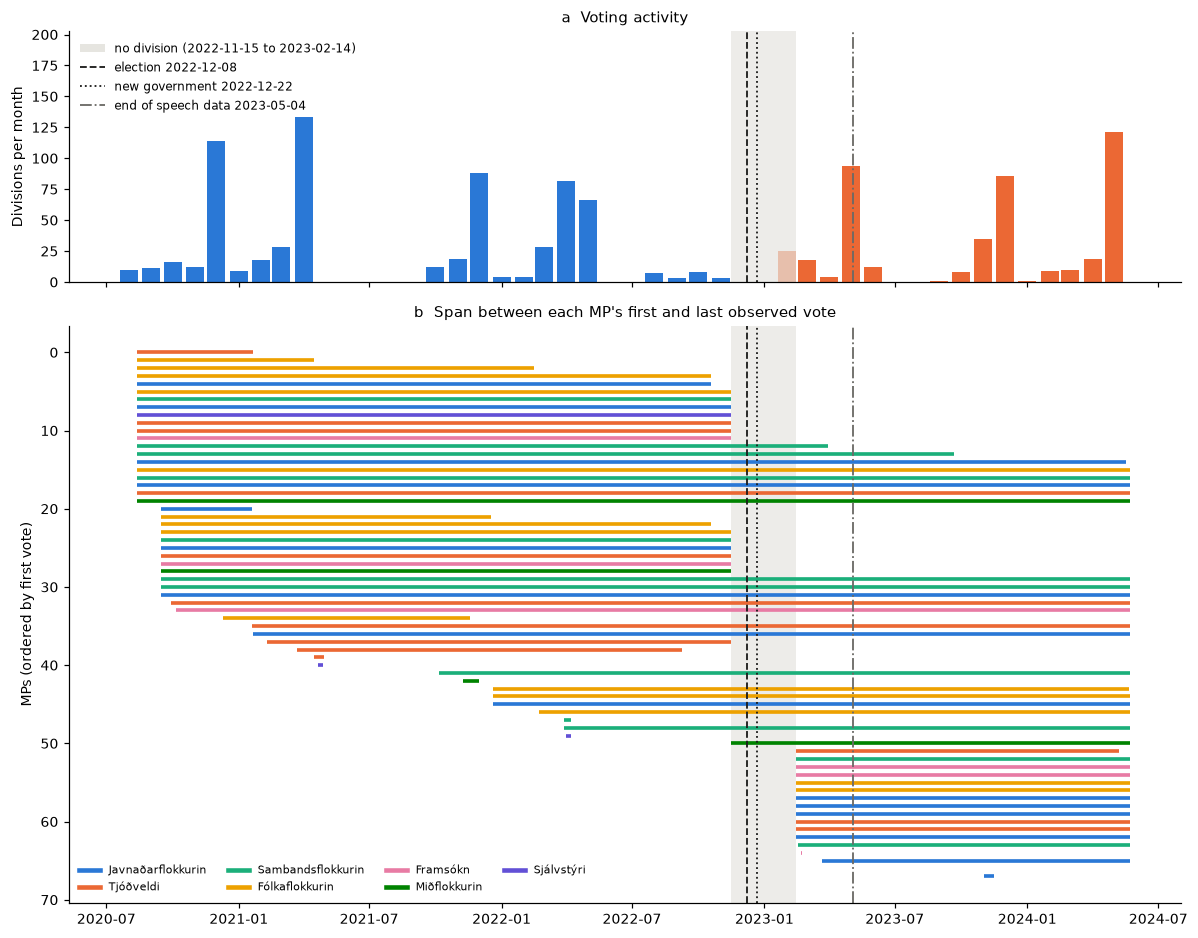

In [23]:
# Figure T1 -- timeline: voting activity and MP spans around the election
fig, ax = plt.subplots(2, 1, figsize=(11, 8.6), sharex=True, gridspec_kw={"height_ratios": [1, 2.3]})
mon = dated.groupby(dated.meeting_date.dt.to_period("M")).size()
x = mon.index.to_timestamp()
ax[0].bar(x, mon.values, width=25, color=np.where(x < T.ELECTION, C_PRE, C_POST))
ax[0].set(ylabel="Divisions per month", title="a  Voting activity")
ax[0].set_ylim(0, ax[0].get_ylim()[1] * 1.45)       # headroom for the legend
spans = cast.groupby("mp_id").meeting_date.agg(["min", "max"]).sort_values(["min", "max"])
spans["party"] = st.party_post.fillna(st.party_pre).reindex(spans.index)
for y, (_, r) in enumerate(spans.iterrows()):
    ax[1].plot([r["min"], r["max"]], [y, y], color=N.PARTY_COLORS[r["party"]], lw=2.4, solid_capstyle="butt")
ax[1].invert_yaxis()
ax[1].set(ylabel="MPs (ordered by first vote)", title="b  Span between each MP's first and last observed vote")
for a in ax:
    a.axvspan(before, after, color="#e6e5e0", alpha=0.7, lw=0)
    a.axvline(T.ELECTION, color=INK, lw=1.2, ls="--")
    a.axvline(T.NEW_GOVERNMENT, color=INK, lw=1.2, ls=":")
    a.axvline(N.WINDOW_END, color=MUTED, lw=1.2, ls="-.")
ax[0].legend(handles=[Patch(facecolor="#e6e5e0", label=f"no division ({before.date()} to {after.date()})"),
                      Line2D([0], [0], color=INK, lw=1.2, ls="--", label=f"election {T.ELECTION.date()}"),
                      Line2D([0], [0], color=INK, lw=1.2, ls=":", label=f"new government {T.NEW_GOVERNMENT.date()}"),
                      Line2D([0], [0], color=MUTED, lw=1.2, ls="-.", label=f"end of speech data {N.WINDOW_END.date()}")],
             loc="upper left", fontsize=8)
ax[1].legend(handles=[Line2D([0], [0], color=N.PARTY_COLORS[p], lw=3, label=p) for p in N.PARTY_ORDER], ncol=4, loc="lower left", fontsize=7)
fig.tight_layout()
save_fig(fig, "figT1_timeline")
plt.show()

In [24]:
caption(f"""**Figure T1.** (a) Divisions per month; orange = after the election. The grey band is the interval with no recorded division (last pre-election vote {before.date()} to first post-election vote {after.date()}); it contains the election (dashed), the new government (dotted) and the winter. The dash-dot line marks the end of the speech data. (b) Each line spans one MP's first to last observed vote (the line does not show individual absences), coloured by the MP's party in the period they were last seen: the turnover of members at the break is visible.""")

**Figure T1.** (a) Divisions per month; orange = after the election. The grey band is the interval with no recorded division (last pre-election vote 2022-11-15 to first post-election vote 2023-02-14); it contains the election (dashed), the new government (dotted) and the winter. The dash-dot line marks the end of the speech data. (b) Each line spans one MP's first to last observed vote (the line does not show individual absences), coloured by the MP's party in the period they were last seen: the turnover of members at the break is visible.

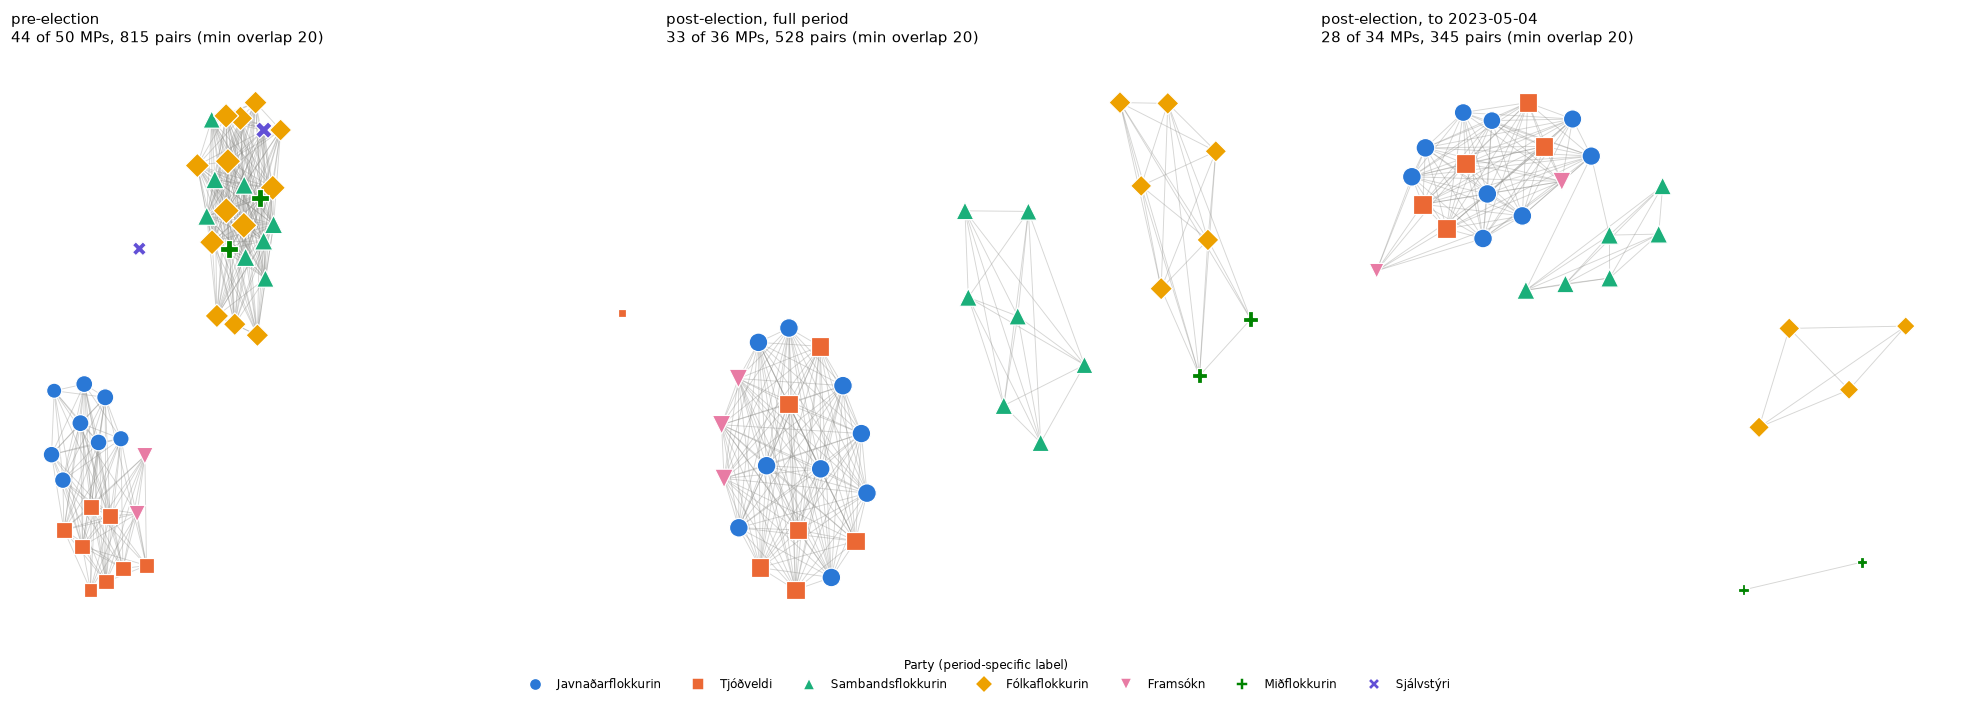

In [25]:
# Figure T2 -- pre vs post networks
def draw(ax, G, title):
    H0 = G.subgraph([n for n, d in G.degree() if d > 0]).copy()
    if H0.number_of_edges() == 0:
        ax.set_title(title, loc="left"); ax.set_axis_off(); return
    pos = nx.kamada_kawai_layout(H0, weight="length")
    H = nx.Graph(); H.add_nodes_from(H0.nodes)
    H.add_edges_from((u, v, d) for u, v, d in H0.edges(data=True) if d["weight"] >= EDGE_SHOW)      # drawing rule only
    nx.draw_networkx_edges(H, pos, ax=ax, width=0.6, edge_color="#8a8a86", alpha=0.35)
    st_ = dict(H0.degree(weight="weight")); smax = max(st_.values())
    for p in N.PARTY_ORDER:
        ns = [n for n in H0 if H0.nodes[n]["party"] == p]
        if ns:
            ax.scatter(*zip(*[pos[n] for n in ns]), s=[30 + 120 * st_[n] / smax for n in ns], c=N.PARTY_COLORS[p],
                       marker=N.PARTY_MARKERS[p], edgecolors="white", linewidths=0.8, zorder=3)
    ax.set_title(title, loc="left"); ax.set_axis_off()

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (k, ttl) in zip(ax, (("pre", "pre-election"), ("post_full", "post-election, full period"), ("post_window", f"post-election, to {N.WINDOW_END.date()}"))):
    s_ = OBJ[k]["stats"]
    draw(a, OBJ[k]["G"], f"{ttl}\n{s_['n_mps_with_edge']} of {s_['n_mps']} MPs, {s_['n_pairs_eligible']} pairs (min overlap {REC})")
present = [p for p in N.PARTY_ORDER if any(p in set(DS[k]["parties"]) for k in DS)]
fig.legend(handles=[Line2D([0], [0], marker=N.PARTY_MARKERS[p], ls="", markersize=8, markeredgecolor="white",
                           markerfacecolor=N.PARTY_COLORS[p], label=p) for p in present], title="Party (period-specific label)",
           loc="lower center", ncol=len(present), fontsize=8, title_fontsize=8, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout()
save_fig(fig, "figT2_pre_post_networks")
plt.show()

In [26]:
caption(f"""**Figure T2.** Voting-similarity networks (nodes: MPs with at least one pair of >= {REC} shared contested divisions; edges drawn: pairs agreeing on >= {EDGE_SHOW:.0%} of them) before the election, after it over the full available period, and after it restricted to the speech-data window. Colour and marker = party label within each period; size = weighted degree. The panels have different MPs; compare structure, not positions.""")

**Figure T2.** Voting-similarity networks (nodes: MPs with at least one pair of >= 20 shared contested divisions; edges drawn: pairs agreeing on >= 80% of them) before the election, after it over the full available period, and after it restricted to the speech-data window. Colour and marker = party label within each period; size = weighted degree. The panels have different MPs; compare structure, not positions.

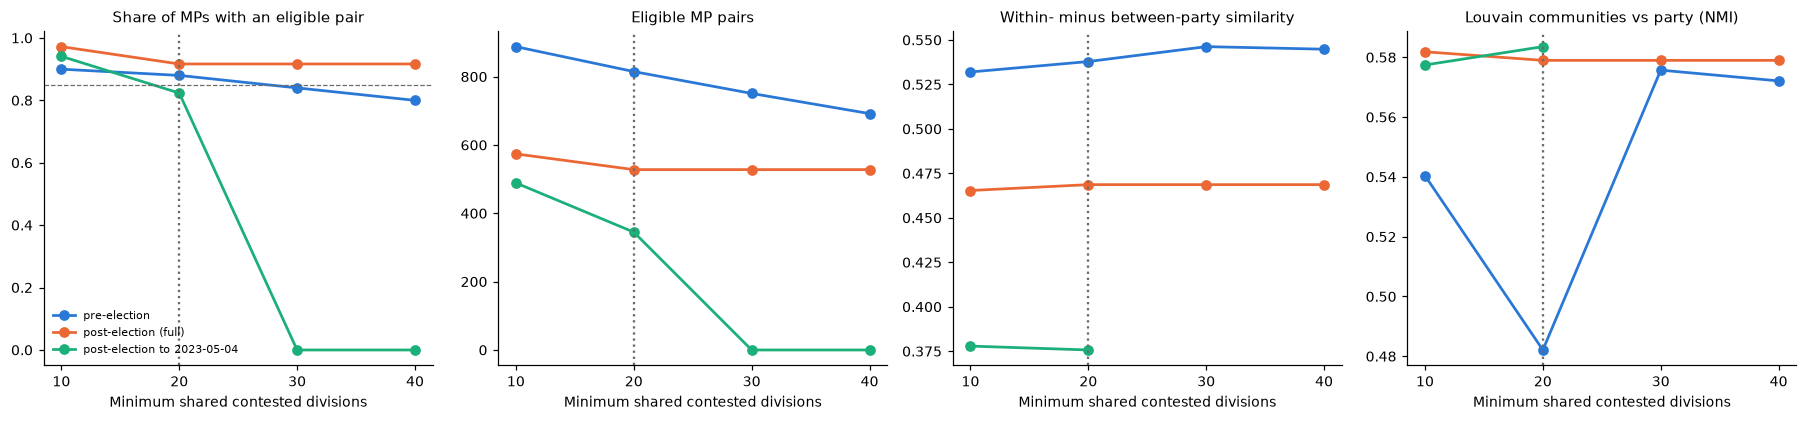

In [27]:
# Figure T3 -- threshold sensitivity
fig, ax = plt.subplots(1, 4, figsize=(16.5, 3.9))
spec = [("share_mps_with_edge", "Share of MPs with an eligible pair"), ("n_pairs_eligible", "Eligible MP pairs"),
        ("gap_within_minus_between", "Within- minus between-party similarity"), ("party_NMI", "Louvain communities vs party (NMI)")]
lines = (("pre", C_PRE, "pre-election"), ("post_full", C_POST, "post-election (full)"), ("post_window", C_WIN, f"post-election to {N.WINDOW_END.date()}"))
for a, (col, ttl) in zip(ax, spec):
    for k, c, lab in lines:
        d = thr_tab[thr_tab.scenario == k]
        a.plot(d.min_overlap, d[col], marker="o", color=c, label=lab, lw=1.8)
    a.axvline(REC, color=MUTED, ls=":")
    a.set(xlabel="Minimum shared contested divisions", title=ttl, xticks=list(THRESHOLDS))
ax[0].axhline(RULE_SHARE, color=MUTED, lw=0.8, ls="--")
ax[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
save_fig(fig, "figT3_threshold_sensitivity")
plt.show()

In [28]:
caption(f"""**Figure T3.** What changes with the overlap threshold ({min(THRESHOLDS)}-{max(THRESHOLDS)}) in each period. Dotted vertical line = recommended threshold ({REC}); dashed horizontal line (left) = the {RULE_SHARE:.0%} coverage rule that selected it. Missing points (post-election to {N.WINDOW_END.date()}, thresholds above {int(thr_tab[(thr_tab.scenario == 'post_window') & thr_tab.n_pairs_eligible.gt(0)].min_overlap.max())}) mean that no pair reaches the threshold, because only {len(DS['post_window']['cols'])} contested divisions fall in that window.""")

**Figure T3.** What changes with the overlap threshold (10-40) in each period. Dotted vertical line = recommended threshold (20); dashed horizontal line (left) = the 85% coverage rule that selected it. Missing points (post-election to 2023-05-04, thresholds above 20) mean that no pair reaches the threshold, because only 26 contested divisions fall in that window.

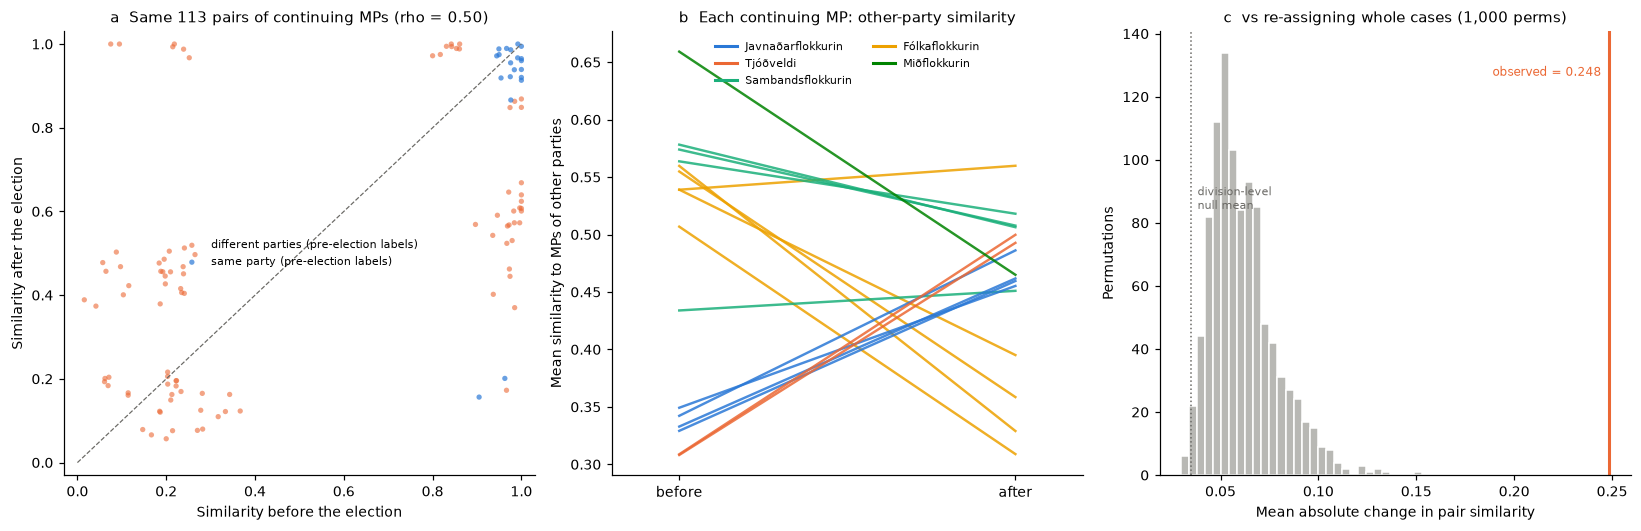

In [29]:
# Figure T4 -- continuing MPs: the same pairs and MPs before vs after
fig, ax = plt.subplots(1, 3, figsize=(15, 4.9))
C_W, C_B = "#2a78d6", "#eb6834"
sp = e.same_party_pre
ax[0].plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
ax[0].scatter(e.similarity_pre[~sp], e.similarity_post[~sp], s=12, color=C_B, alpha=0.6, label="different parties (pre-election labels)", edgecolors="none")
ax[0].scatter(e.similarity_pre[sp], e.similarity_post[sp], s=12, color=C_W, alpha=0.7, label="same party (pre-election labels)", edgecolors="none")
ax[0].set(xlabel="Similarity before the election", ylabel="Similarity after the election", xlim=(-0.03, 1.03), ylim=(-0.03, 1.03),
          title=f"a  Same {len(e)} pairs of continuing MPs (rho = {rho:.2f})")
ax[0].legend(fontsize=7, loc="center")

q = cm.dropna(subset=["mean_sim_other_parties_pre", "mean_sim_other_parties_post"])
for _, r_ in q.iterrows():
    ax[1].plot([0, 1], [r_.mean_sim_other_parties_pre, r_.mean_sim_other_parties_post], color=N.PARTY_COLORS[r_.party_pre], lw=1.6, alpha=0.85)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["before", "after"]); ax[1].set_xlim(-0.2, 1.2)
ax[1].set(ylabel="Mean similarity to MPs of other parties", title="b  Each continuing MP: other-party similarity")
ax[1].legend(handles=[Line2D([0], [0], color=N.PARTY_COLORS[p], lw=2, label=p) for p in N.PARTY_ORDER if p in set(q.party_pre)], fontsize=7, ncol=2, loc="upper center")

ax[2].hist(null_block.mean_abs_change.dropna(), bins=30, color="#b8b8b4", edgecolor="white")
ax[2].axvline(obs_ch["mean_abs_change"], color=C_B, lw=2)
ax[2].set(xlabel="Mean absolute change in pair similarity", ylabel="Permutations",
          title=f"c  vs re-assigning whole cases ({PERM_SPLIT:,} perms)")
ax[2].annotate(f"observed = {obs_ch['mean_abs_change']:.3f}", (obs_ch["mean_abs_change"], ax[2].get_ylim()[1] * 0.9), xytext=(-5, 0),
               textcoords="offset points", ha="right", color=C_B, fontsize=8)
ax[2].axvline(null_divn.mean_abs_change.mean(), color=MUTED, lw=1, ls=":")
ax[2].annotate("division-level\nnull mean", (null_divn.mean_abs_change.mean(), ax[2].get_ylim()[1] * 0.6), xytext=(4, 0),
               textcoords="offset points", ha="left", color=MUTED, fontsize=7)
fig.tight_layout()
save_fig(fig, "figT4_continuing_mps")
plt.show()

In [30]:
caption(f"""**Figure T4.** The continuing MPs only ({len(cont)} MPs, {len(e)} pairs eligible in both periods). (a) Similarity of the same MP pairs before and after the election; points on the dashed diagonal did not change. (b) Each continuing MP's mean similarity to MPs of other parties before and after (line colour = party before). (c) The observed mean absolute change in pair similarity against its distribution when **whole cases** are re-assigned at random to a pseudo-pre / pseudo-post group of the same size ({PERM_SPLIT:,} permutations, the same pairs); the dotted line marks the mean of the cruder null that re-assigns individual divisions. Both nulls ignore time, so they measure only whether the change exceeds sampling variation of the split.""")

**Figure T4.** The continuing MPs only (19 MPs, 113 pairs eligible in both periods). (a) Similarity of the same MP pairs before and after the election; points on the dashed diagonal did not change. (b) Each continuing MP's mean similarity to MPs of other parties before and after (line colour = party before). (c) The observed mean absolute change in pair similarity against its distribution when **whole cases** are re-assigned at random to a pseudo-pre / pseudo-post group of the same size (1,000 permutations, the same pairs); the dotted line marks the mean of the cruder null that re-assigns individual divisions. Both nulls ignore time, so they measure only whether the change exceeds sampling variation of the split.

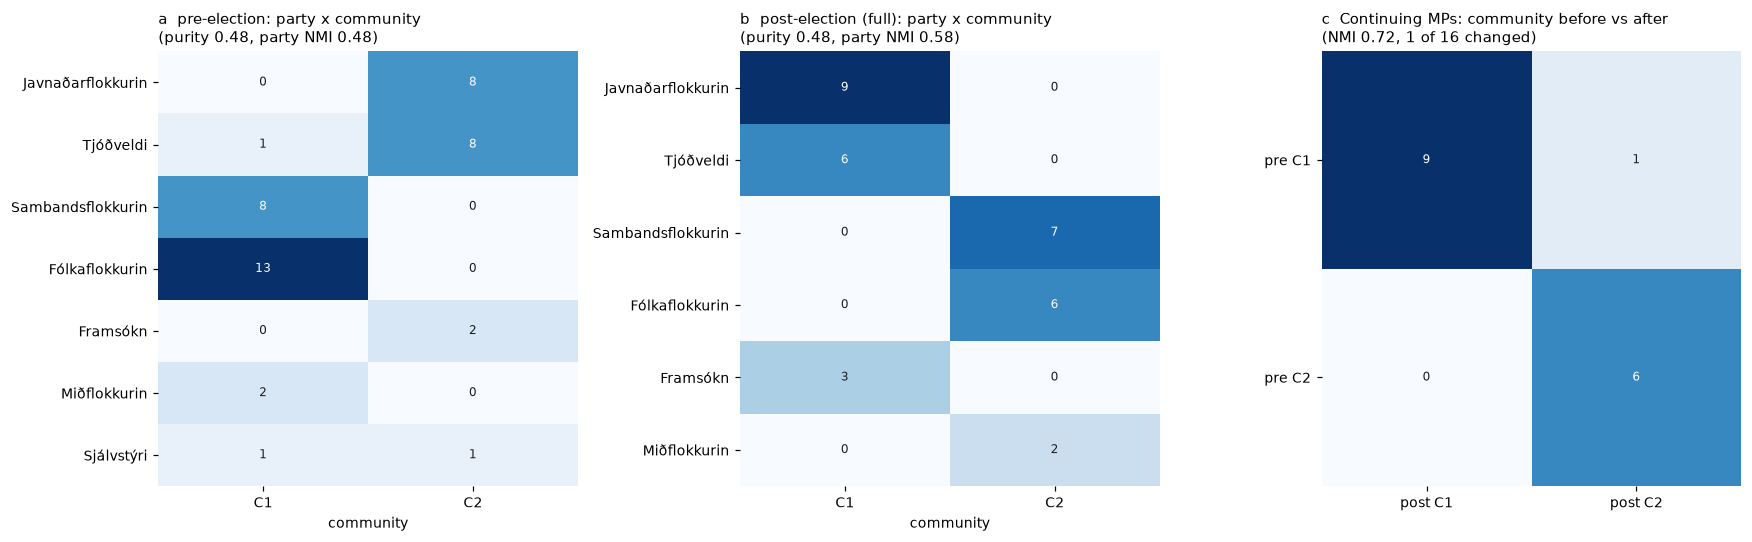

In [31]:
# Figure T5 -- communities by party, and community overlap of the continuing MPs
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
def heat(a, ct, title, xlabel="community", ylabel=None):
    a.imshow(ct.to_numpy(), cmap="Blues", aspect="auto")
    a.set_xticks(range(ct.shape[1])); a.set_xticklabels(ct.columns); a.set_yticks(range(ct.shape[0])); a.set_yticklabels(ct.index)
    for (r_, c_), v_ in np.ndenumerate(ct.to_numpy()):
        a.text(c_, r_, v_, ha="center", va="center", color="white" if v_ > ct.to_numpy().max() / 2 else INK, fontsize=8)
    a.set_title(title, loc="left"); a.set_xlabel(xlabel); a.spines[["left", "bottom"]].set_visible(False)
    if ylabel: a.set_ylabel(ylabel)
for a, (k, ttl) in zip(ax[:2], (("pre", "pre-election"), ("post_full", "post-election (full)"))):
    df = OBJ[k]["comm_df"]
    ct = pd.crosstab(df.party, df.community).reindex([p for p in N.PARTY_ORDER if p in set(df.party)])
    rp = reports[k]
    heat(a, ct, f"{'ab'[k == 'post_full']}  {ttl}: party x community\n(purity {rp['party_purity']:.2f}, party NMI {rp['party_NMI']:.2f})")
ct2 = ct_c.copy(); ct2.index = [f"pre C{i + 1}" for i in range(ct2.shape[0])]; ct2.columns = [f"post C{j + 1}" for j in range(ct2.shape[1])]
heat(ax[2], ct2, f"c  Continuing MPs: community before vs after\n(NMI {nmi_c:.2f}, {int(sum(changed.values()))} of {len(nodes_c)} changed)", xlabel="")
fig.tight_layout()
save_fig(fig, "figT5_communities")
plt.show()

**Figure T5.** (a, b) How many MPs of each party fall in each Louvain community in each period (same-pair threshold, best of 20 seeds). (c) For continuing MPs, the overlap between their community before and after the election (same-pair networks; community numbers are arbitrary labels within each period).

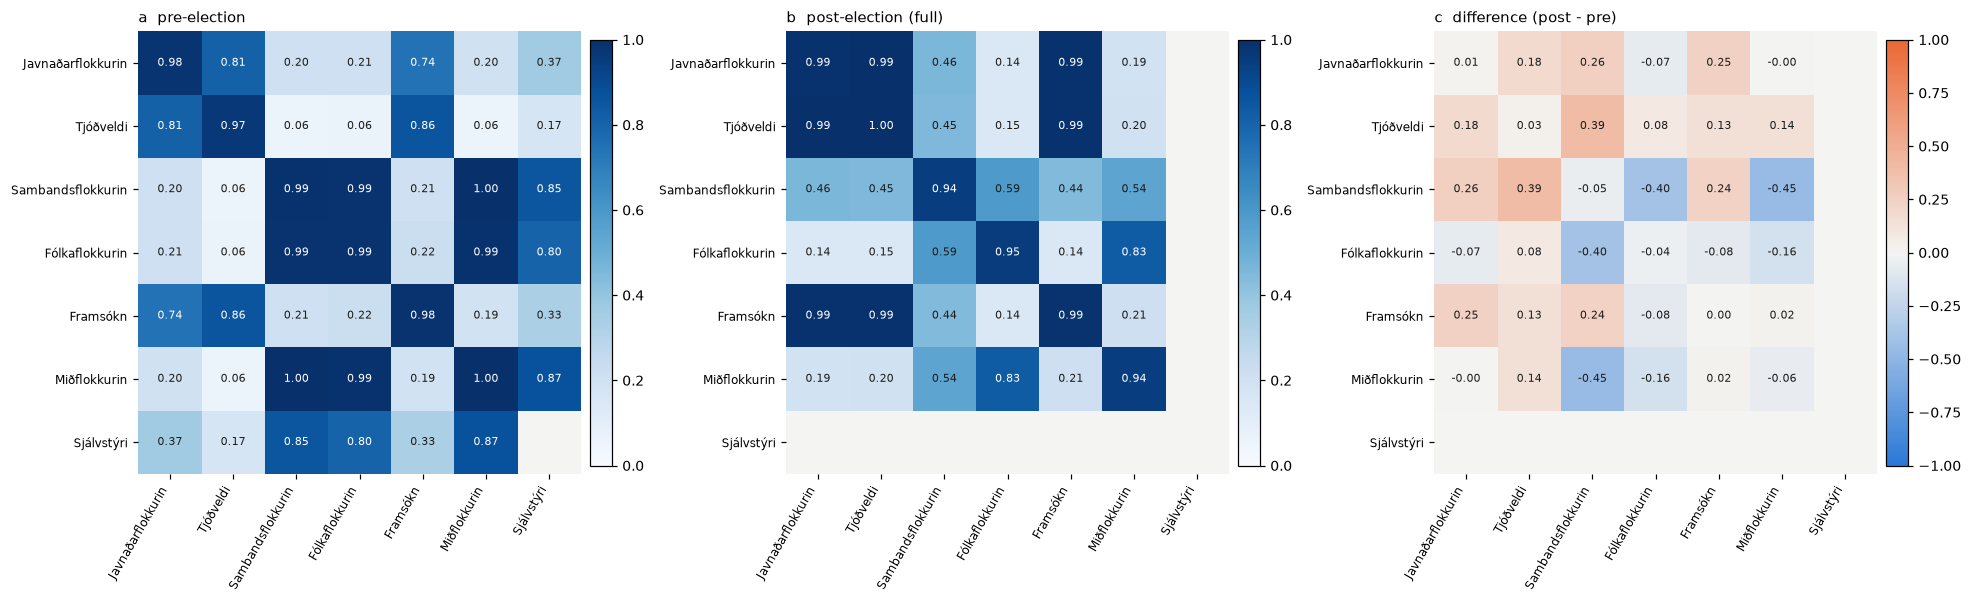

In [32]:
# Figure T6 -- party-by-party similarity before / after and the difference
from matplotlib.colors import LinearSegmentedColormap
def party_matrix(col):
    M_ = pd.DataFrame(np.nan, index=N.PARTY_ORDER, columns=N.PARTY_ORDER)
    for r_ in party_cmp.itertuples(index=False):
        v_ = getattr(r_, col)
        M_.loc[r_.party_a, r_.party_b] = M_.loc[r_.party_b, r_.party_a] = v_
    return M_
mats = {"pre-election": party_matrix("mean_similarity_pre"), "post-election (full)": party_matrix("mean_similarity_post_full")}
mats["difference (post - pre)"] = mats["post-election (full)"] - mats["pre-election"]
div_cmap = LinearSegmentedColormap.from_list("d", ["#2a78d6", "#f4f4f2", "#eb6834"])
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
for a, (ttl, M_) in zip(ax, mats.items()):
    diff = ttl.startswith("difference")
    cmap = (div_cmap if diff else plt.get_cmap("Blues")).copy(); cmap.set_bad("#f4f4f2")
    im = a.imshow(np.ma.masked_invalid(M_.to_numpy()), cmap=cmap, vmin=-1 if diff else 0, vmax=1)
    a.set_xticks(range(7)); a.set_xticklabels(N.PARTY_ORDER, rotation=60, ha="right", fontsize=8)
    a.set_yticks(range(7)); a.set_yticklabels(N.PARTY_ORDER, fontsize=8)
    for (r_, c_), v_ in np.ndenumerate(M_.to_numpy()):
        if np.isfinite(v_):
            a.text(c_, r_, f"{v_:.2f}", ha="center", va="center", fontsize=7, color="white" if (not diff and v_ > 0.6) else INK)
    a.set_title(("abc"[list(mats).index(ttl)]) + "  " + ttl, loc="left"); a.spines[["left", "bottom"]].set_visible(False)
    fig.colorbar(im, ax=a, fraction=0.045, pad=0.02)
fig.tight_layout()
save_fig(fig, "figT6_party_similarity")
plt.show()

**Figure T6.** Mean voting similarity between MPs of each pair of parties (pairs meeting the threshold), before and after the election, and the difference. Blank = no eligible pair of MPs; a party cell reflects only the MPs of that party present in that period, so differences mix behaviour with composition (see section 6 for the continuing-MP comparison).

## 10. A common MP-pair sample for the speech comparison

In [33]:
caption(f"""The temporal analysis uses the recommended threshold ({REC}); the **speech comparison does not have to use the same one**, and it compares *pooled* voting similarity with speech similarity, not pre-election with post-election.

**How the sample is selected.** Start from every pair of the MPs who voted in the pooled speech window ({N.WINDOW_START.date()} to {N.WINDOW_END.date()}, {len(DS['pre']['cols']) + len(DS['post_window']['cols'])} contested divisions; table `network_analysis/outputs/tables/pairwise_voting_similarity.csv`, read-only). A pair enters the sample when it has **at least {COMMON_THR} shared contested divisions in the pooled window** (both MPs cast For or Against; blank and absent excluded), whatever the period. `similarity` and `n_shared_divisions` are the pooled values, so they mix the two parliaments; for each pair the file also gives the number of shared divisions before the election and in the post-election part of the window, and flags for eligibility in each period. The first four columns follow the shared schema `mp_id_1, mp_id_2, similarity, n_shared_divisions` (`mp_id_1 < mp_id_2`, `mp_id` is the key that matches the speech data).""")

The temporal analysis uses the recommended threshold (20); the **speech comparison does not have to use the same one**, and it compares *pooled* voting similarity with speech similarity, not pre-election with post-election.

**How the sample is selected.** Start from every pair of the MPs who voted in the pooled speech window (2020-07-29 to 2023-05-04, 333 contested divisions; table `outputs/network_analysis/tables/pairwise_voting_similarity.csv`, read-only). A pair enters the sample when it has **at least 20 shared contested divisions in the pooled window** (both MPs cast For or Against; blank and absent excluded), whatever the period. `similarity` and `n_shared_divisions` are the pooled values, so they mix the two parliaments; for each pair the file also gives the number of shared divisions before the election and in the post-election part of the window, and flags for eligibility in each period. The first four columns follow the shared schema `mp_id_1, mp_id_2, similarity, n_shared_divisions` (`mp_id_1 < mp_id_2`, `mp_id` is the key that matches the speech data).

In [34]:
base = pd.read_csv(ROOT / "network_analysis" / "outputs" / "tables" / "pairwise_voting_similarity.csv")      # existing output, read-only
pre_t, win_t = EXPORT_PAIRS["pre"], EXPORT_PAIRS["post_window"]
keys = ["mp_id_1", "mp_id_2"]
allp = (base[keys + ["similarity", "n_shared_divisions", "n_matching", "party_1", "party_2", "same_party"]]
        .rename(columns={"n_matching": "n_matching_pooled", "same_party": "same_party_pooled_label"})
        .merge(pre_t[keys + ["similarity", "n_shared_divisions", "n_matching"]].rename(
            columns={"similarity": "similarity_pre", "n_shared_divisions": "n_shared_pre", "n_matching": "n_matching_pre"}), on=keys, how="left")
        .merge(win_t[keys + ["similarity", "n_shared_divisions", "n_matching"]].rename(
            columns={"similarity": "similarity_post_to_2023_05_04", "n_shared_divisions": "n_shared_post_to_2023_05_04",
                     "n_matching": "n_matching_post_to_2023_05_04"}), on=keys, how="left"))
for c in ("n_shared_pre", "n_shared_post_to_2023_05_04", "n_matching_pre", "n_matching_post_to_2023_05_04"):
    allp[c] = allp[c].fillna(0).astype(int)
# consistency: the pooled window is exactly the pre period plus the post period up to the end of the window
assert (allp.n_shared_divisions == allp.n_shared_pre + allp.n_shared_post_to_2023_05_04).all()
assert (allp.n_matching_pooled == allp.n_matching_pre + allp.n_matching_post_to_2023_05_04).all()
allp["eligible_pooled"] = allp.n_shared_divisions >= COMMON_THR
allp["eligible_pre"] = allp.n_shared_pre >= COMMON_THR
allp["eligible_post_to_2023_05_04"] = allp.n_shared_post_to_2023_05_04 >= COMMON_THR
allp["eligible_in_both_periods"] = allp.eligible_pre & allp.eligible_post_to_2023_05_04
common = allp[allp.eligible_pooled].drop(columns="eligible_pooled").reset_index(drop=True)
assert list(common.columns[:4]) == ["mp_id_1", "mp_id_2", "similarity", "n_shared_divisions"] and (common.mp_id_1 < common.mp_id_2).all()
save_table(common, "common_pair_sample.csv")
sample_mps = set(common.mp_id_1) | set(common.mp_id_2)
window_mps = set(base.mp_id_1) | set(base.mp_id_2)
left_out = sorted(window_mps - sample_mps)

# why so few pairs are eligible in BOTH periods: the post-election part of the speech window has very few contested divisions
valid = Mc.isin([1, -1])
n_post_div = len(DS["post_window"]["cols"])
att = pd.DataFrame({"valid contested votes before the election": valid.loc[:, list(DS["pre"]["cols"])].sum(axis=1),
                    "valid contested votes after, to 2023-05-04": valid.loc[:, list(DS["post_window"]["cols"])].sum(axis=1)})
fun10 = pd.Series({"all pairs of MPs voting in the window": len(allp),
                   f"pairs with >= {COMMON_THR} shared divisions, pooled window (= the sample)": int(allp.eligible_pooled.sum()),
                   f"pairs with >= {COMMON_THR} shared divisions before the election": int(allp.eligible_pre.sum()),
                   f"pairs with >= {COMMON_THR} shared divisions after the election, to 2023-05-04": int(allp.eligible_post_to_2023_05_04.sum()),
                   "pairs eligible in both periods": int(allp.eligible_in_both_periods.sum())}, name="pairs")
display(fun10.to_frame())
n_mp_post = int((att.iloc[:, 1] >= COMMON_THR).sum())
caption(f"""**Why only {int(allp.eligible_in_both_periods.sum())} pairs are eligible in both periods.** The post-election part of the speech window contains only **{n_post_div} contested divisions**, so a pair needs to have voted together in at least {COMMON_THR} of them, i.e. {COMMON_THR / n_post_div:.0%} joint attendance. Only {n_mp_post} MPs cast {COMMON_THR} or more valid votes in that stretch (against {int((att.iloc[:, 0] >= COMMON_THR).sum())} before the election), and a pair also needs {COMMON_THR} shared divisions before the election. The pooled sample has no such restriction, because a pair's shared divisions can come from either period; this is why the pooled sample ({len(common)} pairs, {len(sample_mps)} of the {len(window_mps)} MPs voting in the window) is much larger than the both-period subset.""")
print(f"MPs voting in the window but in no sample pair ({len(left_out)}): {[names.get(m, m) for m in left_out]}")
print("their valid contested votes in the window:", [int(att.sum(axis=1).get(m, 0)) for m in left_out])

# compatibility with the speech data: the key is the same MP id; coverage of the sample MPs among the FPSC speakers
fp = pd.read_parquet(ROOT / "data" / "fpsc" / "fpsc_train_metadata.parquet", columns=["mp_id", "contribution_type", "text"])   # read-only
fp = fp[fp.contribution_type.isin(["speaker", "remark"])]
words = fp.groupby("mp_id").text.apply(lambda s: int(s.str.split().str.len().sum()))
MIN_WORDS = 5000                                     # information only: not used to select pairs
has_speech = set(words.index) & sample_mps
enough = {m for m in sample_mps if words.get(m, 0) >= MIN_WORDS}
pairs_enough = int((common.mp_id_1.isin(enough) & common.mp_id_2.isin(enough)).sum())
cov = {"sample_mps": len(sample_mps), "sample_mps_with_any_speaker_or_remark_row": len(has_speech),
       f"sample_mps_with_>={MIN_WORDS}_words": len(enough), "sample_pairs": len(common),
       f"sample_pairs_with_both_MPs_>={MIN_WORDS}_words": pairs_enough,
       "mp_ids_in_sample_missing_from_FPSC": sorted(sample_mps - set(words.index))}
display(pd.Series(cov, name="value").astype(str).to_frame())
common_summary = {"threshold_pooled_window": COMMON_THR, "n_pairs": len(common), "n_mps": len(sample_mps), "n_mps_voting_in_window": len(window_mps),
                  "n_pairs_eligible_pre": int(allp.eligible_pre.sum()), "n_pairs_eligible_post_to_2023_05_04": int(allp.eligible_post_to_2023_05_04.sum()),
                  "n_pairs_eligible_in_both_periods": int(allp.eligible_in_both_periods.sum()),
                  "n_mps_in_both_period_pairs": len(set(allp[allp.eligible_in_both_periods].mp_id_1) | set(allp[allp.eligible_in_both_periods].mp_id_2)),
                  "n_contested_divisions_post_to_2023_05_04": n_post_div, "n_mps_with_enough_votes_post_window": n_mp_post,
                  "n_continuing_mps": len(cont), "fpsc_coverage": cov}
print({k: v for k, v in common_summary.items() if k != "fpsc_coverage"})
R["common_pair_sample"] = common_summary

,pairs
all pairs of MPs voting in the window,2145
"pairs with >= 20 shared divisions, pooled window (= the sample)",1081
pairs with >= 20 shared divisions before the election,815
"pairs with >= 20 shared divisions after the election, to 2023-05-04",345
pairs eligible in both periods,84


**Why only 84 pairs are eligible in both periods.** The post-election part of the speech window contains only **26 contested divisions**, so a pair needs to have voted together in at least 20 of them, i.e. 77% joint attendance. Only 28 MPs cast 20 or more valid votes in that stretch (against 44 before the election), and a pair also needs 20 shared divisions before the election. The pooled sample has no such restriction, because a pair's shared divisions can come from either period; this is why the pooled sample (1081 pairs, 58 of the 66 MPs voting in the window) is much larger than the both-period subset.

MPs voting in the window but in no sample pair (8): ['Kaj Leo Holm Johannesen', 'Sámal Hanni Lognberg', 'Sámal Petur í Grund', 'Tordur J. Niclasen', 'Sólvit E Nolsø', 'Bárður á Lakjuni', 'Magna Eliana Mørkøre', 'Feilur Feilur']
their valid contested votes in the window: [17, 3, 1, 0, 14, 14, 0, 4]


,value
sample_mps,58
sample_mps_with_any_speaker_or_remark_row,58
sample_mps_with_>=5000_words,53
sample_pairs,1081
sample_pairs_with_both_MPs_>=5000_words,941
mp_ids_in_sample_missing_from_FPSC,[]


{'threshold_pooled_window': 20, 'n_pairs': 1081, 'n_mps': 58, 'n_mps_voting_in_window': 66, 'n_pairs_eligible_pre': 815, 'n_pairs_eligible_post_to_2023_05_04': 345, 'n_pairs_eligible_in_both_periods': 84, 'n_mps_in_both_period_pairs': 14, 'n_contested_divisions_post_to_2023_05_04': 26, 'n_mps_with_enough_votes_post_window': 28, 'n_continuing_mps': 19}


## 11. Export summary and final checks

In [35]:
save_table(thr_tab[["scenario", "min_overlap", "n_mps", "n_mps_with_edge", "n_pairs_eligible", "density", "n_components", "largest_component",
                    "mean_within", "mean_between", "gap_within_minus_between", "party_assortativity", "louvain_n_communities",
                    "louvain_modularity", "party_NMI"]].round(6), "temporal_network_metrics.csv")
nodes_rows = []
for k in ("pre", "post_full", "post_window"):
    G, part = OBJ[k]["G"], OBJ[k]["part"]
    bet = nx.betweenness_centrality(G, weight="length", normalized=True)
    cdf = OBJ[k]["comm_df"].set_index("mp_id").community
    for n in G.nodes:
        nodes_rows.append({"period": k, "mp_id": n, "name": names.get(n), "party": G.nodes[n]["party"],
                           "n_contested_votes": int(DS[k]["M"].loc[n].notna().sum()), "degree": G.degree(n),
                           "strength": G.degree(n, weight="weight"), "betweenness": bet[n], "community": cdf.get(n, "isolated")})
save_table(pd.DataFrame(nodes_rows).round(6), "temporal_node_metrics.csv")

R["recommendation"] = {"temporal_threshold": REC, "speech_common_sample_threshold": COMMON_THR,
                       "pairwise_file_for_speech": "network_analysis/outputs/tables/temporal/common_pair_sample.csv (pooled window); full pooled table: network_analysis/outputs/tables/pairwise_voting_similarity.csv"}
res_path = N.output_path(ROOT, OUT, "temporal_results.json")
def to_py(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o.date())
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))
res_path.write_text(json.dumps(R, indent=2, default=to_py, ensure_ascii=False), encoding="utf-8")
print("wrote", res_path.relative_to(ROOT))

# nothing outside the */temporal/ output folders may have changed
after_digest = digest(ROOT)
assert after_digest == EXISTING_BEFORE, "an existing output changed!"
print(f"existing outputs unchanged: {len(after_digest)} files identical to the start of this notebook")

rows = []
for p in sorted([q for k in ("tables", "figures", "results") for q in (ROOT / "network_analysis" / "outputs" / k / OUT).rglob("*")] + [ROOT / "network_analysis" / "reports" / n for n in ("election_timeline.md", "temporal_summary.md")]):
    if p.is_file():
        info = ""
        if p.suffix == ".csv":
            d = pd.read_csv(p); info = f"{d.shape[0]} rows x {d.shape[1]} cols"
        rows.append({"file": str(p.relative_to(ROOT)).replace("\\", "/"), "size_kB": round(p.stat().st_size / 1024, 1), "content": info})
display(pd.DataFrame(rows))

wrote outputs\networks\temporal\temporal_results.json
existing outputs unchanged: 21 files identical to the start of this notebook


,file,size_kB,content
0,outputs/network_analysis/temporal/common_pair_sample.csv,133.3,1081 rows x 17 cols
1,outputs/network_analysis/temporal/community_stability.csv,0.8,12 rows x 9 cols
2,outputs/network_analysis/temporal/composition_vs_conti...,1.0,12 rows x 8 cols
3,outputs/network_analysis/temporal/continuing_mp_compar...,3.4,19 rows x 21 cols
4,outputs/network_analysis/temporal/continuing_mp_funnel...,1.6,22 rows x 7 cols
5,outputs/network_analysis/temporal/continuing_mp_pair_c...,25.8,171 rows x 18 cols
6,outputs/network_analysis/temporal/election_timeline.md,3.4,
7,outputs/network_analysis/temporal/figures/figT1_timeli...,23.7,
8,outputs/network_analysis/temporal/figures/figT1_timeli...,179.9,
9,outputs/network_analysis/temporal/figures/figT2_pre_po...,30.5,


## 12. What changed, what stayed, what is robust

The next cell builds the summary text from the objects computed above (no number is typed by hand) and saves it as `network_analysis/reports/temporal_summary.md`. The wording around the numbers is a reading of them; the assertions at the end of the cell fail if a specific claim made in the wording stops being true of the data.

In [36]:
cvb = R["composition_vs_behaviour"]
ALL, CONT, COMP = "post_minus_pre, all MPs", "post_minus_pre, continuing MPs", "difference attributable to who is in parliament"
comp_ = R["composition_comparison"]
pre_s, post_s, win_s = comp_["pre"], comp_["post_full"], comp_["post_window"]
nul_div, nul_pty = R["null_within_division"]["results"], R["null_party_label"]["results"]
ct_, cs_ = R["continuing"], R["null_continuing"]
ct_["n_mps_eligible"] = R["continuing_funnel"][next(k for k in R["continuing_funnel"] if k.startswith("... with an eligible pair"))]
cs_ns = cs_["excluding_party_changers"]
sp_ = cs_["split_null_primary"]
sp_t = sp_["table"]
bm_ = cs_["within_period_split_half_benchmark"]["results"]
dv_t = cs_["split_null_reference_division_level"]["table"]
com = R["communities"]
pc = party_cmp.dropna(subset=["change_post_full_minus_pre"]).query("n_pairs_pre >= 10 and n_pairs_post_full >= 10")
dn, up = pc.nsmallest(3, "change_post_full_minus_pre"), pc.nlargest(3, "change_post_full_minus_pre")
fmt = lambda d: "; ".join(f"{r.party_a}-{r.party_b} {r.mean_similarity_pre:.2f} -> {r.mean_similarity_post_full:.2f}" for r in d.itertuples())
thr_rng = thr_tab[thr_tab.scenario.isin(["pre", "post_full"])]
tm = R["timeline"]

SUMMARY = f"""# Temporal extension: voting networks around the 8 December 2022 Løgting election

*Generated by `network_analysis/notebooks/04_temporal_network_analysis.ipynb`; every number below is computed from the data. No causal claim is made.*

## Timeline (see `election_timeline.md` for sources)

* Election 8 Dec 2022 and new government 22 Dec 2022 (government.fo). Last division before the election: **{tm['last_vote_before_election']}**; first after: **{tm['first_vote_after_election']}** ({tm['days_between']} days later); divisions dated 8-22 Dec: **{tm['votes_between_election_and_new_government']}**. The data cannot separate the election, the change of government and the winter break.
* MPs: {R['mp_transitions']['continuing']} continuing, {R['mp_transitions'].get('left (pre only)')} left, {R['mp_transitions'].get('entered (post only)')} entered; {R['mp_transitions']['party_changers']} continuing MP changed party label.

## Networks (threshold {REC} shared contested divisions; {R['threshold']['rule']})

| | pre-election | post-election (full) | post-election to 4 May 2023 |
|---|---|---|---|
| contested divisions | {pre_s['n_divisions']} | {post_s['n_divisions']} | {win_s['n_divisions']} |
| MPs (with an eligible pair) | {pre_s['n_mps']} ({pre_s['n_mps_with_edge']}) | {post_s['n_mps']} ({post_s['n_mps_with_edge']}) | {win_s['n_mps']} ({win_s['n_mps_with_edge']}) |
| eligible pairs / density | {pre_s['n_pairs_eligible']} / {pre_s['density']:.2f} | {post_s['n_pairs_eligible']} / {post_s['density']:.2f} | {win_s['n_pairs_eligible']} / {win_s['density']:.2f} |
| mean similarity within / between parties | {pre_s['mean_within']:.3f} / {pre_s['mean_between']:.3f} | {post_s['mean_within']:.3f} / {post_s['mean_between']:.3f} | {win_s['mean_within']:.3f} / {win_s['mean_between']:.3f} |
| within-minus-between gap | {pre_s['gap_within_minus_between']:.3f} | {post_s['gap_within_minus_between']:.3f} | {win_s['gap_within_minus_between']:.3f} |
| weighted party assortativity | {pre_s['party_assortativity_weighted']:.3f} | {post_s['party_assortativity_weighted']:.3f} | {win_s['party_assortativity_weighted']:.3f} |
| Louvain communities / modularity | {pre_s['louvain_n_communities']} / {pre_s['louvain_modularity']:.3f} | {post_s['louvain_n_communities']} / {post_s['louvain_modularity']:.3f} | {win_s['louvain_n_communities']} / {win_s['louvain_modularity']:.3f} |
| party NMI of communities | {pre_s['party_NMI']:.3f} | {post_s['party_NMI']:.3f} | {win_s['party_NMI']:.3f} |
| NMI with sourced coalition membership (hypothesis) | {com['pre']['NMI_with_sourced_coalition_membership']:.2f} | {com['post_full']['NMI_with_sourced_coalition_membership']:.2f} | {com['post_window']['NMI_with_sourced_coalition_membership']:.2f} |

## What changed

* **Party structure weakened, bloc structure persisted.** The within-minus-between gap fell from {pre_s['gap_within_minus_between']:.3f} to {post_s['gap_within_minus_between']:.3f} and Louvain modularity from {pre_s['louvain_modularity']:.3f} to {post_s['louvain_modularity']:.3f}; between-party similarity rose from {pre_s['mean_between']:.3f} to {post_s['mean_between']:.3f}. The rough comparison with label-shuffle noise does not call the full-period gap change distinguishable (p = {nul_pty['diff_post_full_minus_pre']['p_two_sided']:.2f}), so this is a descriptive difference.
* **Largest party-pair changes** (mean similarity pre -> post): decreases: {fmt(dn)}. Increases: {fmt(up)}.

## What stayed similar

* Same-party MPs vote almost identically in both periods (mean within-party similarity {pre_s['mean_within']:.3f} and {post_s['mean_within']:.3f}); party labels carry information in each period (party-label permutation p = {nul_pty['pre']['p_upper']:.4f} and {nul_pty['post_full']['p_upper']:.4f}).
* Louvain finds **{pre_s['louvain_n_communities']} communities in every period and threshold**, stable across 20 seeds (NMI between runs {thr_rng.louvain_stability_NMI.min():.2f}-{thr_rng.louvain_stability_NMI.max():.2f}); each period's two communities are made of essentially the same two sets of parties (the exceptions are one Tjóðveldi MP and the small Sjálvstýri party in the pre-election communities; see Figure T5).
* MP-specific structure exceeds what division tallies and attendance imply in every period (within-division shuffle: modularity {nul_div['pre']['louvain_Q']['observed']:.3f} vs null {nul_div['pre']['louvain_Q']['null mean']:.3f} pre; {nul_div['post_full']['louvain_Q']['observed']:.3f} vs {nul_div['post_full']['louvain_Q']['null mean']:.3f} post; p <= {max(v['louvain_Q']['p (upper)'] for v in nul_div.values()):.3f}).

## Composition vs behaviour

Change in each statistic between the two periods, for all MPs, for the continuing MPs only, and the part attributable to *who is in parliament* (all-MP change minus continuing-MP change):

| statistic | all MPs | continuing MPs | attributable to composition |
|---|---|---|---|
| within-minus-between gap | {cvb[ALL]['gap_within_minus_between']:+.3f} | {cvb[CONT]['gap_within_minus_between']:+.3f} | {cvb[COMP]['gap_within_minus_between']:+.3f} |
| mean between-party similarity | {cvb[ALL]['mean_between']:+.3f} | {cvb[CONT]['mean_between']:+.3f} | {cvb[COMP]['mean_between']:+.3f} |
| Louvain modularity | {cvb[ALL]['louvain_modularity']:+.3f} | {cvb[CONT]['louvain_modularity']:+.3f} | {cvb[COMP]['louvain_modularity']:+.3f} |
| party NMI | {cvb[ALL]['party_NMI']:+.3f} | {cvb[CONT]['party_NMI']:+.3f} | {cvb[COMP]['party_NMI']:+.3f} |

Most of the change in these *network-level summaries* is therefore associated with the different set of MPs, not with the continuing MPs.

## Continuing MPs ({R['mp_transitions']['continuing']} voted in both periods; {ct_['n_mps']} have contested votes in both; {ct_['n_pairs_eligible_both']} pairs eligible in both periods)

* **Pair-level similarity changed a lot while the average barely moved.** Mean change {ct_['mean_change']:+.3f} but mean absolute change **{sp_['observed']['mean_abs_change']:.3f}**, against {sp_t['mean_abs_change']['null mean']:.3f} +/- {sp_t['mean_abs_change']['null sd']:.3f} (maximum {sp_t['mean_abs_change']['null max']:.3f}) when whole cases are re-assigned at random to pseudo-periods ({sp_['n_perm']:,} permutations, same {sp_['pairs_in_observed_set']} pairs; p = {sp_t['mean_abs_change']['p (two-sided vs null mean)']:.3f}, the smallest attainable). Random halves *within* one period (a conservative benchmark) give {bm_['pre-election only']['mean abs change (mean)']:.3f} (pre) and {bm_['post-election only']['mean abs change (mean)']:.3f} (post), and independent-vote sampling noise at the observed pair sizes {cs_['binomial_noise_expected_mean_abs_change']['mean']:.3f}. The rank correlation of the same pairs before vs after is **{ct_['spearman_pre_post']:.2f}** (Mantel p = {cs_['mantel']['p_upper']:.4f}); the null rank correlation, i.e. how reproducible the pair similarities are when only the sample of cases changes, is {sp_t['spearman_pre_post']['null mean']:.2f} (lowest {sp_t['spearman_pre_post']['null min']:.2f}). Excluding the party-changing MP: mean absolute change {cs_ns['observed']['mean_abs_change']:.3f}, correlation {cs_ns['observed']['spearman_pre_post']:.2f}. At thresholds {min(THRESHOLDS)}-{max(THRESHOLDS)} the observed mean absolute change stays between {min(v['mean_abs_change'] for v in cs_['observed_by_threshold'].values() if v['mean_abs_change'] == v['mean_abs_change']):.3f} and {max(v['mean_abs_change'] for v in cs_['observed_by_threshold'].values() if v['mean_abs_change'] == v['mean_abs_change']):.3f}. This shows that the pair similarities are *different* in the two sets of cases beyond sampling variation; it does not say why (agenda, roles, time).
* **Communities of the same MPs largely persist:** NMI between pre and post communities {ct_['nmi_pre_vs_post_communities']:.2f}; {ct_['n_mps_community_changed']} of {ct_['n_mps_compared_communities']} MPs changed community ({', '.join(m[0] for m in R['communities_continuing']['changed'])}).

## Government/opposition: a hypothesis, not a result

Official sources fix the dates only; the coalition parties come from secondary sources. *If* they are right, essentially the same two sets of parties formed the two communities before and after the election while their government/opposition roles reversed, so which parties group together is not simply a matter of governing vs opposing; what changed (descriptively) is cohesion: the bloc that moved into opposition became less cohesive (largest decreases above) and the new government's parties became more cohesive (Javnaðarflokkurin-Framsókn and Tjóðveldi-Framsókn rise to about 0.99). The communities match the sourced coalition membership with NMI {com['pre']['NMI_with_sourced_coalition_membership']:.2f} (pre) and {com['post_full']['NMI_with_sourced_coalition_membership']:.2f} (post). This is consistent with a role effect but equally with composition, agenda and time; it is not tested.

## Dependence on the overlap threshold

Over thresholds 10-40 the within-minus-between gap stays within {thr_rng.groupby('scenario').gap_within_minus_between.apply(lambda s: s.max() - s.min()).max():.3f} and Louvain finds 2 communities throughout (pre and post full). The party NMI of the pre-election communities is the one statistic that moves ({thr_rng[thr_rng.scenario == 'pre'].party_NMI.min():.2f}-{thr_rng[thr_rng.scenario == 'pre'].party_NMI.max():.2f}), because a few MPs with little overlap flip communities. Coverage is the real trade-off: at 40 only {thr_tab.query("scenario == 'pre' and min_overlap == 40").share_mps_with_edge.iloc[0]:.0%} of pre-election MPs have an eligible pair; at 20, {thr_tab.query("scenario == 'pre' and min_overlap == 20").share_mps_with_edge.iloc[0]:.0%} (pre) and {thr_tab.query("scenario == 'post_full' and min_overlap == 20").share_mps_with_edge.iloc[0]:.0%} (post). **Recommended temporal threshold: {REC}.** The speech window holds only {win_s['n_divisions']} contested post-election divisions, so thresholds of 30 and 40 are impossible there.

## Robust vs exploratory

* **Robust (tested, and unchanged in headline terms across thresholds 10-40, seeds and the contested rule):** strong party signal in each period; two stable communities in each period; MP-specific structure beyond division tallies; same-pair similarities among continuing MPs changed by far more than re-assigning whole cases at random, or random halves within one period, produce (the observed change is also not explained by the one MP who changed party).
* **Exploratory:** the government/opposition reading; which party pairs changed and why; the composition/behaviour decomposition (one decomposition, no uncertainty interval; {ct_['n_mps']} continuing MPs); the continuing-MP community comparison ({ct_['n_mps_compared_communities']} MPs); everything about the post-election window to 4 May 2023 ({win_s['n_divisions']} contested divisions).

## Limitations

* No causal claim: the pre/post contrast also reflects the agenda, the calendar, different MPs, (reportedly) substitutes taking ministers' seats, and (according to secondary sources) changed government/opposition roles.
* The {tm['days_between']}-day gap with no divisions contains the election, the new government and the winter; the data cannot separate them.
* Period-specific party labels are the modal label within each period; {R['mp_transitions']['party_changers']} continuing MP changed party.
* The null for "the same MPs changed" ignores time and does not keep each MP's period-specific attendance; the party-gap difference null ignores sampling variability of the similarities.
* The pair-level comparison covers {ct_['n_mps_eligible']} MPs and {ct_['n_pairs_eligible_both']} pairs; MPs with little overlap in one period are not in it (see `continuing_mp_funnel.csv`).

## For the speech workstream

* **File to use:** `network_analysis/outputs/tables/temporal/common_pair_sample.csv` (shared schema in the first four columns). It holds **{R['common_pair_sample']['n_pairs']} pairs among {R['common_pair_sample']['n_mps']} of the {R['common_pair_sample']['n_mps_voting_in_window']} MPs** who voted in the speech window: every pair with >= {R['common_pair_sample']['threshold_pooled_window']} shared contested divisions in the pooled window ({N.WINDOW_START.date()} to {N.WINDOW_END.date()}). `similarity` and `n_shared_divisions` are pooled over both parliaments.
* **Period-specific columns** (`similarity_pre`, `similarity_post_to_2023_05_04`, shared counts and eligibility flags) are there for optional per-period work. Only **{R['common_pair_sample']['n_pairs_eligible_in_both_periods']} pairs ({R['common_pair_sample']['n_mps_in_both_period_pairs']} MPs)** are eligible in both periods, because the post-election part of the window has just {R['common_pair_sample']['n_contested_divisions_post_to_2023_05_04']} contested divisions (a pair needs {R['common_pair_sample']['threshold_pooled_window']} of them jointly); per-period comparisons are therefore feasible mainly before the election.
* **Match with the speech data:** {R['common_pair_sample']['fpsc_coverage']['sample_mps_with_any_speaker_or_remark_row']} of the {R['common_pair_sample']['n_mps']} sample MPs have speaker/remark rows in the local FPSC metadata (same `mp_id` key); the speech workstream should apply its own minimum-speech rule.
* The pooled similarity mixes two parliaments and is bimodal, so compare within the two blocs or control for party/bloc. The temporal voting threshold ({REC}) need not be the speech threshold; the speech comparison should state its own.
"""
p = N.output_path(ROOT, OUT, "temporal_summary.md")
p.write_text(SUMMARY, encoding="utf-8")
display(Markdown(SUMMARY))

# guards for claims made in the prose above
BLOC_A, BLOC_B = {"Sambandsflokkurin", "Fólkaflokkurin", "Miðflokkurin"}, {"Javnaðarflokkurin", "Tjóðveldi", "Framsókn"}
def bloc_exceptions(k):
    df = OBJ[k]["comm_df"]
    df = df[df.party.isin(BLOC_A | BLOC_B)].assign(bloc_a=lambda d: d.party.isin(BLOC_A))
    majority = df.groupby("bloc_a").community.agg(lambda c: c.value_counts().idxmax())
    return df[df.community != df.bloc_a.map(majority)]
exc_pre, exc_post = bloc_exceptions("pre"), bloc_exceptions("post_full")
assert len(exc_post) == 0 and list(exc_pre.party) == ["Tjóðveldi"], "prose about 'essentially the same two sets of parties' is stale"
assert OBJ["pre"]["comm_df"].query("party == 'Sjálvstýri'").community.nunique() == 2
assert dn.iloc[0].party_a == "Sambandsflokkurin" or dn.iloc[0].party_b == "Sambandsflokkurin", "prose about the largest decrease is stale"
assert com["pre"]["n_communities"] == 2 and com["post_full"]["n_communities"] == 2
assert (thr_rng.louvain_n_communities == 2).all() and cvb[ALL]["gap_within_minus_between"] < 0
print("\ninterpretation guards passed; wrote", p.relative_to(ROOT))

# Temporal extension: voting networks around the 8 December 2022 Løgting election

*Generated by `notebooks/04_temporal_network_analysis.ipynb`; every number below is computed from the data. No causal claim is made.*

## Timeline (see `election_timeline.md` for sources)

* Election 8 Dec 2022 and new government 22 Dec 2022 (government.fo). Last division before the election: **2022-11-15**; first after: **2023-02-14** (91 days later); divisions dated 8-22 Dec: **0**. The data cannot separate the election, the change of government and the winter break.
* MPs: 22 continuing, 29 left, 17 entered; 1 continuing MP changed party label.

## Networks (threshold 20 shared contested divisions; largest threshold with pre and post_full both >= 85% of MPs having an eligible pair)

| | pre-election | post-election (full) | post-election to 4 May 2023 |
|---|---|---|---|
| contested divisions | 307 | 249 | 26 |
| MPs (with an eligible pair) | 50 (44) | 36 (33) | 34 (28) |
| eligible pairs / density | 815 / 0.67 | 528 / 0.84 | 345 / 0.61 |
| mean similarity within / between parties | 0.983 / 0.445 | 0.974 / 0.505 | 0.983 / 0.607 |
| within-minus-between gap | 0.538 | 0.469 | 0.376 |
| weighted party assortativity | 0.126 | 0.095 | 0.026 |
| Louvain communities / modularity | 2 / 0.318 | 2 / 0.212 | 2 / 0.077 |
| party NMI of communities | 0.482 | 0.579 | 0.584 |
| NMI with sourced coalition membership (hypothesis) | 0.86 | 1.00 | 1.00 |

## What changed

* **Party structure weakened, bloc structure persisted.** The within-minus-between gap fell from 0.538 to 0.469 and Louvain modularity from 0.318 to 0.212; between-party similarity rose from 0.445 to 0.505. The rough comparison with label-shuffle noise does not call the full-period gap change distinguishable (p = 0.19), so this is a descriptive difference.
* **Largest party-pair changes** (mean similarity pre -> post): decreases: Sambandsflokkurin-Miðflokkurin 1.00 -> 0.54; Sambandsflokkurin-Fólkaflokkurin 0.99 -> 0.59; Fólkaflokkurin-Miðflokkurin 0.99 -> 0.83. Increases: Tjóðveldi-Sambandsflokkurin 0.06 -> 0.45; Javnaðarflokkurin-Sambandsflokkurin 0.20 -> 0.46; Javnaðarflokkurin-Framsókn 0.74 -> 0.99.

## What stayed similar

* Same-party MPs vote almost identically in both periods (mean within-party similarity 0.983 and 0.974); party labels carry information in each period (party-label permutation p = 0.0001 and 0.0001).
* Louvain finds **2 communities in every period and threshold**, stable across 20 seeds (NMI between runs 1.00-1.00); each period's two communities are made of essentially the same two sets of parties (the exceptions are one Tjóðveldi MP and the small Sjálvstýri party in the pre-election communities; see Figure T5).
* MP-specific structure exceeds what division tallies and attendance imply in every period (within-division shuffle: modularity 0.318 vs null 0.027 pre; 0.212 vs -0.000 post; p <= 0.001).

## Composition vs behaviour

Change in each statistic between the two periods, for all MPs, for the continuing MPs only, and the part attributable to *who is in parliament* (all-MP change minus continuing-MP change):

| statistic | all MPs | continuing MPs | attributable to composition |
|---|---|---|---|
| within-minus-between gap | -0.069 | -0.032 | -0.038 |
| mean between-party similarity | +0.060 | +0.015 | +0.046 |
| Louvain modularity | -0.106 | -0.029 | -0.077 |
| party NMI | +0.097 | -0.020 | +0.117 |

Most of the change in these *network-level summaries* is therefore associated with the different set of MPs, not with the continuing MPs.

## Continuing MPs (22 voted in both periods; 19 have contested votes in both; 113 pairs eligible in both periods)

* **Pair-level similarity changed a lot while the average barely moved.** Mean change -0.009 but mean absolute change **0.248**, against 0.062 +/- 0.017 (maximum 0.153) when whole cases are re-assigned at random to pseudo-periods (1,000 permutations, same 113 pairs; p = 0.001, the smallest attainable). Random halves *within* one period (a conservative benchmark) give 0.064 (pre) and 0.066 (post), and independent-vote sampling noise at the observed pair sizes 0.039. The rank correlation of the same pairs before vs after is **0.50** (Mantel p = 0.0038); the null rank correlation, i.e. how reproducible the pair similarities are when only the sample of cases changes, is 0.97 (lowest 0.88). Excluding the party-changing MP: mean absolute change 0.187, correlation 0.68. At thresholds 10-40 the observed mean absolute change stays between 0.246 and 0.263. This shows that the pair similarities are *different* in the two sets of cases beyond sampling variation; it does not say why (agenda, roles, time).
* **Communities of the same MPs largely persist:** NMI between pre and post communities 0.72; 1 of 16 MPs changed community (Annika Olsen).

## Government/opposition: a hypothesis, not a result

Official sources fix the dates only; the coalition parties come from secondary sources. *If* they are right, essentially the same two sets of parties formed the two communities before and after the election while their government/opposition roles reversed, so which parties group together is not simply a matter of governing vs opposing; what changed (descriptively) is cohesion: the bloc that moved into opposition became less cohesive (largest decreases above) and the new government's parties became more cohesive (Javnaðarflokkurin-Framsókn and Tjóðveldi-Framsókn rise to about 0.99). The communities match the sourced coalition membership with NMI 0.86 (pre) and 1.00 (post). This is consistent with a role effect but equally with composition, agenda and time; it is not tested.

## Dependence on the overlap threshold

Over thresholds 10-40 the within-minus-between gap stays within 0.014 and Louvain finds 2 communities throughout (pre and post full). The party NMI of the pre-election communities is the one statistic that moves (0.48-0.58), because a few MPs with little overlap flip communities. Coverage is the real trade-off: at 40 only 80% of pre-election MPs have an eligible pair; at 20, 88% (pre) and 92% (post). **Recommended temporal threshold: 20.** The speech window holds only 26 contested post-election divisions, so thresholds of 30 and 40 are impossible there.

## Robust vs exploratory

* **Robust (tested, and unchanged in headline terms across thresholds 10-40, seeds and the contested rule):** strong party signal in each period; two stable communities in each period; MP-specific structure beyond division tallies; same-pair similarities among continuing MPs changed by far more than re-assigning whole cases at random, or random halves within one period, produce (the observed change is also not explained by the one MP who changed party).
* **Exploratory:** the government/opposition reading; which party pairs changed and why; the composition/behaviour decomposition (one decomposition, no uncertainty interval; 19 continuing MPs); the continuing-MP community comparison (16 MPs); everything about the post-election window to 4 May 2023 (26 contested divisions).

## Limitations

* No causal claim: the pre/post contrast also reflects the agenda, the calendar, different MPs, (reportedly) substitutes taking ministers' seats, and (according to secondary sources) changed government/opposition roles.
* The 91-day gap with no divisions contains the election, the new government and the winter; the data cannot separate them.
* Period-specific party labels are the modal label within each period; 1 continuing MP changed party.
* The null for "the same MPs changed" ignores time and does not keep each MP's period-specific attendance; the party-gap difference null ignores sampling variability of the similarities.
* The pair-level comparison covers 16 MPs and 113 pairs; MPs with little overlap in one period are not in it (see `continuing_mp_funnel.csv`).

## For the speech workstream

* **File to use:** `outputs/network_analysis/temporal/common_pair_sample.csv` (shared schema in the first four columns). It holds **1081 pairs among 58 of the 66 MPs** who voted in the speech window: every pair with >= 20 shared contested divisions in the pooled window (2020-07-29 to 2023-05-04). `similarity` and `n_shared_divisions` are pooled over both parliaments.
* **Period-specific columns** (`similarity_pre`, `similarity_post_to_2023_05_04`, shared counts and eligibility flags) are there for optional per-period work. Only **84 pairs (14 MPs)** are eligible in both periods, because the post-election part of the window has just 26 contested divisions (a pair needs 20 of them jointly); per-period comparisons are therefore feasible mainly before the election.
* **Match with the speech data:** 58 of the 58 sample MPs have speaker/remark rows in the local FPSC metadata (same `mp_id` key); the speech workstream should apply its own minimum-speech rule.
* The pooled similarity mixes two parliaments and is bimodal, so compare within the two blocs or control for party/bloc. The temporal voting threshold (20) need not be the speech threshold; the speech comparison should state its own.



interpretation guards passed; wrote outputs\networks\temporal\temporal_summary.md
